In [1]:
import pandas as pd
import csv
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error as mse
from sklearn.preprocessing import StandardScaler
import time

## Initial Data Import

In [ ]:
pd.set_option('display.max_rows', 500)
data = pd.read_csv('../MD_csvs/polymer_chi_database.csv')
data

In [ ]:
gtt_data = pd.read_csv('../MD_csvs/glass_transition_temp.csv')
gtt_data

In [4]:
data.isna().sum()

Polymer             0
Nickname          321
Si                  0
N                   0
chi0                0
chi0v               0
chi1                0
chi1v               0
chi0v_Si            0
chi1v_Si            0
density           209
molar_volume      209
N_MV              209
delta_avg         313
E_coh_fedors      218
E_coh_krevelen    218
dtype: int64

## Krevelen Cohesive Energy

In [ ]:
X_krev = (
    data.dropna(subset=['E_coh_krevelen'])
        [['chi0', 'chi1', 'chi0v_Si', 'chi1v_Si']]
)
X_krev

In [ ]:
y_krev = (
    data.dropna(subset=['E_coh_krevelen'])
        [['E_coh_krevelen']]
)
y_krev

In [7]:
print(min(data.dropna(subset=['E_coh_krevelen'])['E_coh_krevelen']))
print(max(data.dropna(subset=['E_coh_krevelen'])['E_coh_krevelen']))

6720.0
263600.0


### Using 10, 10 size

In [20]:
# from sklearn.metrics import r2_score, mean_squared_error as mse
# import numpy as np

X_train, X_test, y_train, y_test = train_test_split(X_krev, y_krev, test_size = 0.2, random_state = 53)

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history = np.zeros((n_runs, n_iters))
rmse_history = np.zeros((n_runs, n_iters))
r2_history = np.zeros((n_runs, n_iters))
start_time = np.zeros(n_runs)
end_time = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train, y_train, epochs=100, verbose=0)

        # Predictions
        y_test_pred = model.predict(X_test).flatten()
        y_train_pred = model.predict(X_train).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history[run, i] = q2
        rmse_history[run, i] = rmse
        r2_history[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time[run] = time.time()
    print('total time:', end_time[run] - start_time[run])
end_time - start_time

Run 1/5
  Iter 0: Q²=-1.619, RMSE=76680.229, R²=-1.429
  Iter 1: Q²=-1.595, RMSE=76314.902, R²=-1.404
  Iter 2: Q²=-1.529, RMSE=75341.494, R²=-1.338
  Iter 3: Q²=-1.413, RMSE=73594.503, R²=-1.222
  Iter 4: Q²=-1.246, RMSE=71007.995, R²=-1.054
  Iter 5: Q²=-1.036, RMSE=67595.223, R²=-0.844
  Iter 6: Q²=-0.788, RMSE=63356.794, R²=-0.597
  Iter 7: Q²=-0.524, RMSE=58480.823, R²=-0.335
  Iter 8: Q²=-0.253, RMSE=53023.744, R²=-0.067
  Iter 9: Q²=0.005, RMSE=47250.295, R²=0.185
  Iter 10: Q²=0.235, RMSE=41430.479, R²=0.407
  Iter 11: Q²=0.423, RMSE=36003.321, R²=0.584
  Iter 12: Q²=0.560, RMSE=31410.518, R²=0.710
  Iter 13: Q²=0.650, RMSE=28014.497, R²=0.788
  Iter 14: Q²=0.700, RMSE=25968.006, R²=0.827
  Iter 15: Q²=0.724, RMSE=24906.162, R²=0.843
  Iter 16: Q²=0.734, RMSE=24456.280, R²=0.848
  Iter 17: Q²=0.737, RMSE=24286.701, R²=0.849
  Iter 18: Q²=0.738, RMSE=24228.146, R²=0.850
  Iter 19: Q²=0.739, RMSE=24208.595, R²=0.850
  Iter 20: Q²=0.739, RMSE=24194.073, R²=0.850
  Iter 21: Q²=0.73

  Iter 77: Q²=0.737, RMSE=24306.247, R²=0.871
  Iter 78: Q²=0.736, RMSE=24322.127, R²=0.871
  Iter 79: Q²=0.736, RMSE=24325.727, R²=0.871
  Iter 80: Q²=0.736, RMSE=24334.808, R²=0.871
  Iter 81: Q²=0.737, RMSE=24307.874, R²=0.871
  Iter 82: Q²=0.737, RMSE=24311.668, R²=0.871
  Iter 83: Q²=0.736, RMSE=24324.240, R²=0.871
  Iter 84: Q²=0.736, RMSE=24345.067, R²=0.871
  Iter 85: Q²=0.736, RMSE=24364.667, R²=0.871
  Iter 86: Q²=0.736, RMSE=24332.511, R²=0.871
  Iter 87: Q²=0.735, RMSE=24389.642, R²=0.871
  Iter 88: Q²=0.736, RMSE=24355.639, R²=0.871
  Iter 89: Q²=0.736, RMSE=24354.239, R²=0.871
  Iter 90: Q²=0.736, RMSE=24334.161, R²=0.871
  Iter 91: Q²=0.735, RMSE=24375.644, R²=0.871
  Iter 92: Q²=0.735, RMSE=24381.432, R²=0.871
  Iter 93: Q²=0.735, RMSE=24393.136, R²=0.871
  Iter 94: Q²=0.735, RMSE=24382.583, R²=0.871
  Iter 95: Q²=0.735, RMSE=24382.346, R²=0.872
  Iter 96: Q²=0.735, RMSE=24390.507, R²=0.872
  Iter 97: Q²=0.735, RMSE=24396.987, R²=0.872
  Iter 98: Q²=0.734, RMSE=24420.08

  Iter 54: Q²=0.741, RMSE=24121.702, R²=0.866
  Iter 55: Q²=0.741, RMSE=24128.367, R²=0.867
  Iter 56: Q²=0.741, RMSE=24125.698, R²=0.867
  Iter 57: Q²=0.741, RMSE=24128.406, R²=0.867
  Iter 58: Q²=0.740, RMSE=24153.921, R²=0.867
  Iter 59: Q²=0.740, RMSE=24140.352, R²=0.867
  Iter 60: Q²=0.740, RMSE=24147.438, R²=0.868
  Iter 61: Q²=0.740, RMSE=24149.063, R²=0.868
  Iter 62: Q²=0.739, RMSE=24185.217, R²=0.868
  Iter 63: Q²=0.740, RMSE=24149.557, R²=0.868
  Iter 64: Q²=0.739, RMSE=24208.821, R²=0.868
  Iter 65: Q²=0.739, RMSE=24199.938, R²=0.868
  Iter 66: Q²=0.739, RMSE=24191.916, R²=0.868
  Iter 67: Q²=0.740, RMSE=24157.788, R²=0.869
  Iter 68: Q²=0.739, RMSE=24216.263, R²=0.869
  Iter 69: Q²=0.739, RMSE=24201.793, R²=0.869
  Iter 70: Q²=0.739, RMSE=24210.354, R²=0.869
  Iter 71: Q²=0.739, RMSE=24224.137, R²=0.869
  Iter 72: Q²=0.739, RMSE=24216.346, R²=0.869
  Iter 73: Q²=0.739, RMSE=24218.960, R²=0.869
  Iter 74: Q²=0.738, RMSE=24235.141, R²=0.870
  Iter 75: Q²=0.738, RMSE=24229.92

array([37.5424819 , 36.65048528, 36.5369463 , 36.60577011, 37.87218595])

In [21]:
# This was from the first run
end_time - start_time

array([37.5424819 , 36.65048528, 36.5369463 , 36.60577011, 37.87218595])

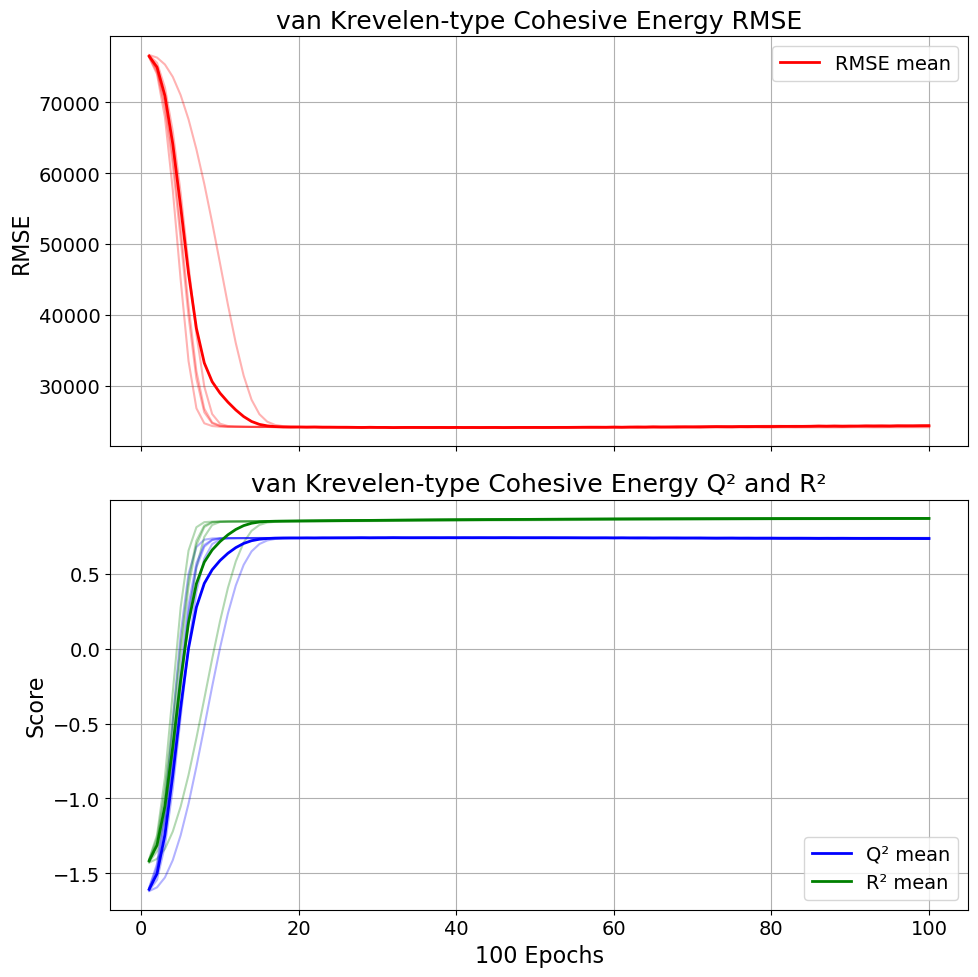

In [22]:
# Average across runs
q2_mean = q2_history.mean(axis=0)
rmse_mean = rmse_history.mean(axis=0)
r2_mean = r2_history.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('van Krevelen-type Cohesive Energy RMSE')
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('100 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('van Krevelen-type Cohesive Energy Q² and R²')
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

In [23]:
print(q2_mean[-1])
print(rmse_mean[-1])
print(r2_mean[-1])

0.7363142021507816
24328.70732319657
0.8705668717604894


### Using 16, 12 NN

In [24]:
n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history = np.zeros((n_runs, n_iters))
rmse_history = np.zeros((n_runs, n_iters))
r2_history = np.zeros((n_runs, n_iters))
start_time = np.zeros(n_runs)
end_time = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
        Dense(12, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train, y_train, epochs=100, verbose=0)

        # Predictions
        y_test_pred = model.predict(X_test).flatten()
        y_train_pred = model.predict(X_train).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history[run, i] = q2
        rmse_history[run, i] = rmse
        r2_history[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time[run] = time.time()
    print('total time:', end_time[run] - start_time[run])
end_time - start_time

Run 1/5
  Iter 0: Q²=-1.608, RMSE=76518.994, R²=-1.418
  Iter 1: Q²=-1.523, RMSE=75262.679, R²=-1.333
  Iter 2: Q²=-1.296, RMSE=71784.374, R²=-1.104
  Iter 3: Q²=-0.909, RMSE=65458.068, R²=-0.717
  Iter 4: Q²=-0.437, RMSE=56799.958, R²=-0.249
  Iter 5: Q²=0.023, RMSE=46842.135, R²=0.202
  Iter 6: Q²=0.385, RMSE=37152.990, R²=0.549
  Iter 7: Q²=0.605, RMSE=29785.604, R²=0.749
  Iter 8: Q²=0.701, RMSE=25907.041, R²=0.828
  Iter 9: Q²=0.730, RMSE=24636.058, R²=0.847
  Iter 10: Q²=0.737, RMSE=24316.631, R²=0.849
  Iter 11: Q²=0.739, RMSE=24211.115, R²=0.850
  Iter 12: Q²=0.739, RMSE=24221.830, R²=0.850
  Iter 13: Q²=0.739, RMSE=24202.824, R²=0.851
  Iter 14: Q²=0.739, RMSE=24210.672, R²=0.851
  Iter 15: Q²=0.739, RMSE=24210.173, R²=0.852
  Iter 16: Q²=0.740, RMSE=24177.358, R²=0.852
  Iter 17: Q²=0.740, RMSE=24172.297, R²=0.853
  Iter 18: Q²=0.739, RMSE=24189.412, R²=0.854
  Iter 19: Q²=0.740, RMSE=24143.029, R²=0.854
  Iter 20: Q²=0.740, RMSE=24138.580, R²=0.855
  Iter 21: Q²=0.740, RMSE=

  Iter 78: Q²=0.736, RMSE=24323.568, R²=0.871
  Iter 79: Q²=0.737, RMSE=24299.312, R²=0.871
  Iter 80: Q²=0.737, RMSE=24298.871, R²=0.871
  Iter 81: Q²=0.737, RMSE=24316.940, R²=0.871
  Iter 82: Q²=0.736, RMSE=24343.600, R²=0.871
  Iter 83: Q²=0.736, RMSE=24336.825, R²=0.871
  Iter 84: Q²=0.737, RMSE=24313.315, R²=0.871
  Iter 85: Q²=0.736, RMSE=24350.574, R²=0.871
  Iter 86: Q²=0.736, RMSE=24349.916, R²=0.871
  Iter 87: Q²=0.736, RMSE=24364.895, R²=0.871
  Iter 88: Q²=0.736, RMSE=24356.384, R²=0.871
  Iter 89: Q²=0.736, RMSE=24333.483, R²=0.871
  Iter 90: Q²=0.736, RMSE=24347.871, R²=0.871
  Iter 91: Q²=0.736, RMSE=24350.322, R²=0.871
  Iter 92: Q²=0.736, RMSE=24362.468, R²=0.871
  Iter 93: Q²=0.735, RMSE=24366.539, R²=0.871
  Iter 94: Q²=0.735, RMSE=24367.996, R²=0.871
  Iter 95: Q²=0.736, RMSE=24358.159, R²=0.871
  Iter 96: Q²=0.735, RMSE=24392.713, R²=0.871
  Iter 97: Q²=0.735, RMSE=24393.403, R²=0.872
  Iter 98: Q²=0.735, RMSE=24369.136, R²=0.872
  Iter 99: Q²=0.735, RMSE=24403.00

  Iter 55: Q²=0.739, RMSE=24203.185, R²=0.869
  Iter 56: Q²=0.739, RMSE=24220.778, R²=0.869
  Iter 57: Q²=0.739, RMSE=24203.652, R²=0.870
  Iter 58: Q²=0.739, RMSE=24196.252, R²=0.870
  Iter 59: Q²=0.738, RMSE=24229.704, R²=0.870
  Iter 60: Q²=0.738, RMSE=24248.277, R²=0.870
  Iter 61: Q²=0.739, RMSE=24224.162, R²=0.870
  Iter 62: Q²=0.738, RMSE=24255.619, R²=0.870
  Iter 63: Q²=0.738, RMSE=24237.988, R²=0.870
  Iter 64: Q²=0.737, RMSE=24296.762, R²=0.870
  Iter 65: Q²=0.738, RMSE=24265.335, R²=0.870
  Iter 66: Q²=0.737, RMSE=24292.139, R²=0.871
  Iter 67: Q²=0.738, RMSE=24274.060, R²=0.871
  Iter 68: Q²=0.737, RMSE=24283.546, R²=0.871
  Iter 69: Q²=0.737, RMSE=24299.897, R²=0.871
  Iter 70: Q²=0.737, RMSE=24294.672, R²=0.871
  Iter 71: Q²=0.736, RMSE=24328.166, R²=0.871
  Iter 72: Q²=0.737, RMSE=24313.212, R²=0.871
  Iter 73: Q²=0.737, RMSE=24308.251, R²=0.871
  Iter 74: Q²=0.737, RMSE=24313.528, R²=0.871
  Iter 75: Q²=0.737, RMSE=24306.684, R²=0.871
  Iter 76: Q²=0.736, RMSE=24335.65

array([37.16393948, 37.12022662, 35.29527593, 38.84854412, 37.6369946 ])

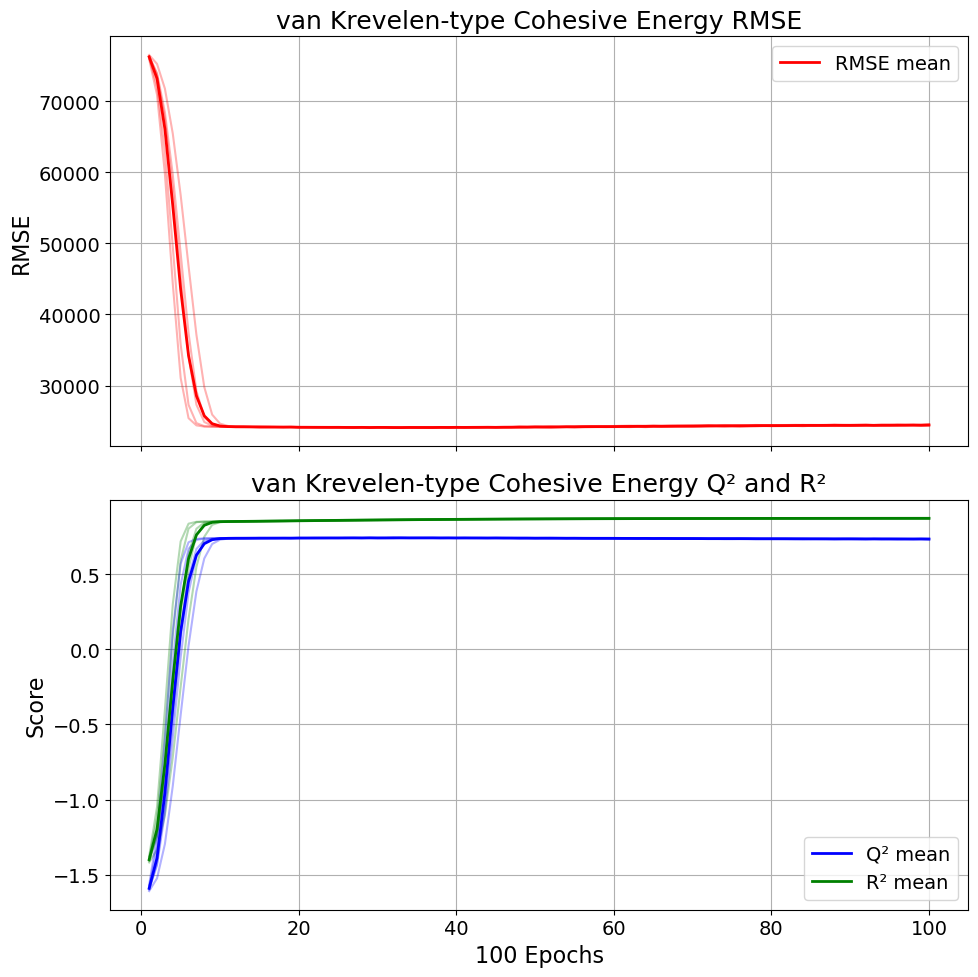

In [25]:
# Average across runs
q2_mean = q2_history.mean(axis=0)
rmse_mean = rmse_history.mean(axis=0)
r2_mean = r2_history.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('van Krevelen-type Cohesive Energy RMSE')
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('100 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('van Krevelen-type Cohesive Energy Q² and R²')
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

### Scaled data using 10, 10 NN

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X_krev, y_krev, test_size = 0.2, random_state = 53)

X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
# y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history = np.zeros((n_runs, n_iters))
rmse_history = np.zeros((n_runs, n_iters))
r2_history = np.zeros((n_runs, n_iters))
start_time = np.zeros(n_runs)
end_time = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train_scaled.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train_scaled, y_train_scaled, epochs=100, verbose=0)

        # Predictions
        y_test_pred_scaled = model.predict(X_test_scaled)
        y_train_pred_scaled = model.predict(X_train_scaled)
        
        y_test_pred = y_scaler.inverse_transform(y_test_pred_scaled).flatten()
        y_train_pred = y_scaler.inverse_transform(y_train_pred_scaled).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history[run, i] = q2
        rmse_history[run, i] = rmse
        r2_history[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time[run] = time.time()
    print('total time:', end_time[run] - start_time[run])
    
print(end_time - start_time)

Run 1/5
  Iter 0: Q²=0.714, RMSE=25339.754, R²=0.882
  Iter 1: Q²=0.718, RMSE=25139.932, R²=0.885
  Iter 2: Q²=0.721, RMSE=25008.366, R²=0.886
  Iter 3: Q²=0.722, RMSE=24995.946, R²=0.887
  Iter 4: Q²=0.722, RMSE=24978.772, R²=0.888
  Iter 5: Q²=0.723, RMSE=24952.535, R²=0.889
  Iter 6: Q²=0.722, RMSE=24966.610, R²=0.890
  Iter 7: Q²=0.720, RMSE=25049.011, R²=0.891
  Iter 8: Q²=0.721, RMSE=25021.082, R²=0.892
  Iter 9: Q²=0.720, RMSE=25054.476, R²=0.893
  Iter 10: Q²=0.720, RMSE=25054.347, R²=0.894
  Iter 11: Q²=0.722, RMSE=24972.701, R²=0.895
  Iter 12: Q²=0.721, RMSE=25010.834, R²=0.896
  Iter 13: Q²=0.721, RMSE=25012.151, R²=0.898
  Iter 14: Q²=0.719, RMSE=25116.261, R²=0.899
  Iter 15: Q²=0.722, RMSE=24963.233, R²=0.900
  Iter 16: Q²=0.721, RMSE=25025.219, R²=0.902
  Iter 17: Q²=0.720, RMSE=25059.335, R²=0.904
  Iter 18: Q²=0.722, RMSE=25000.118, R²=0.906
  Iter 19: Q²=0.724, RMSE=24884.411, R²=0.908
  Iter 20: Q²=0.726, RMSE=24818.683, R²=0.909
  Iter 21: Q²=0.719, RMSE=25121.427,

  Iter 78: Q²=0.604, RMSE=29822.278, R²=0.965
  Iter 79: Q²=0.607, RMSE=29686.150, R²=0.967
  Iter 80: Q²=0.599, RMSE=30011.782, R²=0.966
  Iter 81: Q²=0.604, RMSE=29825.615, R²=0.967
  Iter 82: Q²=0.607, RMSE=29720.050, R²=0.967
  Iter 83: Q²=0.605, RMSE=29761.238, R²=0.967
  Iter 84: Q²=0.600, RMSE=29948.743, R²=0.968
  Iter 85: Q²=0.598, RMSE=30028.187, R²=0.968
  Iter 86: Q²=0.589, RMSE=30363.567, R²=0.968
  Iter 87: Q²=0.595, RMSE=30148.106, R²=0.968
  Iter 88: Q²=0.603, RMSE=29853.529, R²=0.968
  Iter 89: Q²=0.595, RMSE=30149.165, R²=0.969
  Iter 90: Q²=0.589, RMSE=30388.782, R²=0.968
  Iter 91: Q²=0.591, RMSE=30296.140, R²=0.969
  Iter 92: Q²=0.590, RMSE=30324.729, R²=0.969
  Iter 93: Q²=0.584, RMSE=30544.145, R²=0.969
  Iter 94: Q²=0.578, RMSE=30761.165, R²=0.969
  Iter 95: Q²=0.575, RMSE=30873.630, R²=0.970
  Iter 96: Q²=0.578, RMSE=30795.442, R²=0.970
  Iter 97: Q²=0.585, RMSE=30508.793, R²=0.970
  Iter 98: Q²=0.585, RMSE=30523.936, R²=0.970
  Iter 99: Q²=0.578, RMSE=30780.37

  Iter 55: Q²=0.638, RMSE=28491.884, R²=0.962
  Iter 56: Q²=0.643, RMSE=28305.914, R²=0.962
  Iter 57: Q²=0.643, RMSE=28289.022, R²=0.962
  Iter 58: Q²=0.632, RMSE=28730.745, R²=0.962
  Iter 59: Q²=0.632, RMSE=28734.815, R²=0.963
  Iter 60: Q²=0.635, RMSE=28604.482, R²=0.962
  Iter 61: Q²=0.631, RMSE=28794.441, R²=0.963
  Iter 62: Q²=0.632, RMSE=28741.826, R²=0.964
  Iter 63: Q²=0.639, RMSE=28447.838, R²=0.963
  Iter 64: Q²=0.639, RMSE=28459.894, R²=0.964
  Iter 65: Q²=0.618, RMSE=29265.253, R²=0.964
  Iter 66: Q²=0.622, RMSE=29122.432, R²=0.964
  Iter 67: Q²=0.633, RMSE=28703.455, R²=0.964
  Iter 68: Q²=0.634, RMSE=28677.927, R²=0.965
  Iter 69: Q²=0.635, RMSE=28614.159, R²=0.965
  Iter 70: Q²=0.632, RMSE=28760.175, R²=0.965
  Iter 71: Q²=0.630, RMSE=28835.385, R²=0.965
  Iter 72: Q²=0.629, RMSE=28847.415, R²=0.966
  Iter 73: Q²=0.635, RMSE=28634.247, R²=0.966
  Iter 74: Q²=0.625, RMSE=28998.378, R²=0.966
  Iter 75: Q²=0.628, RMSE=28893.832, R²=0.967
  Iter 76: Q²=0.619, RMSE=29229.30

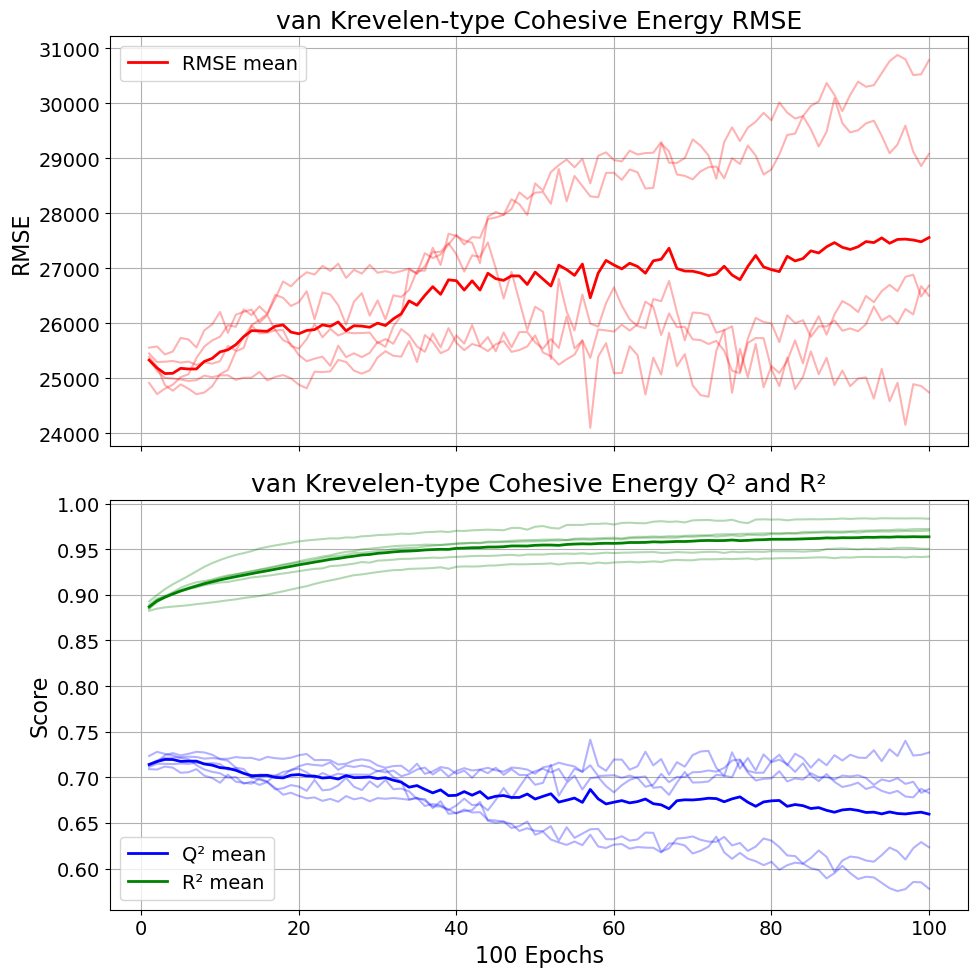

In [27]:
# Average across runs
q2_mean = q2_history.mean(axis=0)
rmse_mean = rmse_history.mean(axis=0)
r2_mean = r2_history.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('van Krevelen-type Cohesive Energy RMSE')
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('100 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('van Krevelen-type Cohesive Energy Q² and R²')
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

In [28]:
print(q2_mean[-1])
print(rmse_mean[-1])
print(r2_mean[-1])

0.6596902358019016
27557.158417569986
0.9635700903441917


### Zoom in on early Epochs

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X_krev, y_krev, test_size = 0.2, random_state = 53)

X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
# y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history = np.zeros((n_runs, n_iters))
rmse_history = np.zeros((n_runs, n_iters))
r2_history = np.zeros((n_runs, n_iters))
start_time = np.zeros(n_runs)
end_time = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train_scaled.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train_scaled, y_train_scaled, epochs=10, verbose=0)

        # Predictions
        y_test_pred_scaled = model.predict(X_test_scaled)
        y_train_pred_scaled = model.predict(X_train_scaled)
        
        y_test_pred = y_scaler.inverse_transform(y_test_pred_scaled).flatten()
        y_train_pred = y_scaler.inverse_transform(y_train_pred_scaled).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history[run, i] = q2
        rmse_history[run, i] = rmse
        r2_history[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time[run] = time.time()
    print('total time:', end_time[run] - start_time[run])
    
print(end_time - start_time)

Run 1/5
  Iter 0: Q²=0.280, RMSE=40208.072, R²=0.324
  Iter 1: Q²=0.559, RMSE=31448.959, R²=0.644
  Iter 2: Q²=0.698, RMSE=26017.067, R²=0.827
  Iter 3: Q²=0.720, RMSE=25049.655, R²=0.863
  Iter 4: Q²=0.722, RMSE=24972.749, R²=0.870
  Iter 5: Q²=0.723, RMSE=24922.051, R²=0.874
  Iter 6: Q²=0.723, RMSE=24948.696, R²=0.878
  Iter 7: Q²=0.721, RMSE=25045.029, R²=0.880
  Iter 8: Q²=0.722, RMSE=24997.575, R²=0.881
  Iter 9: Q²=0.722, RMSE=24962.924, R²=0.882
  Iter 10: Q²=0.722, RMSE=24983.454, R²=0.883
  Iter 11: Q²=0.723, RMSE=24952.097, R²=0.883
  Iter 12: Q²=0.723, RMSE=24924.041, R²=0.884
  Iter 13: Q²=0.723, RMSE=24938.231, R²=0.884
  Iter 14: Q²=0.724, RMSE=24876.210, R²=0.885
  Iter 15: Q²=0.725, RMSE=24843.656, R²=0.885
  Iter 16: Q²=0.724, RMSE=24879.343, R²=0.885
  Iter 17: Q²=0.725, RMSE=24834.744, R²=0.885
  Iter 18: Q²=0.723, RMSE=24923.503, R²=0.886
  Iter 19: Q²=0.724, RMSE=24881.285, R²=0.886
  Iter 20: Q²=0.725, RMSE=24849.207, R²=0.887
  Iter 21: Q²=0.723, RMSE=24915.092,

  Iter 78: Q²=0.712, RMSE=25405.273, R²=0.909
  Iter 79: Q²=0.712, RMSE=25419.674, R²=0.909
  Iter 80: Q²=0.711, RMSE=25450.120, R²=0.909
  Iter 81: Q²=0.710, RMSE=25523.966, R²=0.909
  Iter 82: Q²=0.712, RMSE=25410.044, R²=0.910
  Iter 83: Q²=0.711, RMSE=25464.024, R²=0.909
  Iter 84: Q²=0.713, RMSE=25399.195, R²=0.909
  Iter 85: Q²=0.713, RMSE=25389.990, R²=0.910
  Iter 86: Q²=0.713, RMSE=25390.791, R²=0.910
  Iter 87: Q²=0.713, RMSE=25372.768, R²=0.910
  Iter 88: Q²=0.711, RMSE=25449.928, R²=0.910
  Iter 89: Q²=0.712, RMSE=25440.601, R²=0.910
  Iter 90: Q²=0.713, RMSE=25383.981, R²=0.911
  Iter 91: Q²=0.713, RMSE=25385.522, R²=0.911
  Iter 92: Q²=0.712, RMSE=25422.941, R²=0.910
  Iter 93: Q²=0.711, RMSE=25475.266, R²=0.911
  Iter 94: Q²=0.713, RMSE=25396.938, R²=0.911
  Iter 95: Q²=0.713, RMSE=25375.091, R²=0.911
  Iter 96: Q²=0.714, RMSE=25358.644, R²=0.911
  Iter 97: Q²=0.713, RMSE=25367.578, R²=0.911
  Iter 98: Q²=0.713, RMSE=25380.950, R²=0.912
  Iter 99: Q²=0.713, RMSE=25383.28

  Iter 56: Q²=0.738, RMSE=24269.541, R²=0.898
  Iter 57: Q²=0.737, RMSE=24279.582, R²=0.898
  Iter 58: Q²=0.739, RMSE=24183.339, R²=0.899
  Iter 59: Q²=0.739, RMSE=24200.016, R²=0.899
  Iter 60: Q²=0.739, RMSE=24203.112, R²=0.899
  Iter 61: Q²=0.738, RMSE=24261.234, R²=0.900
  Iter 62: Q²=0.739, RMSE=24205.831, R²=0.900
  Iter 63: Q²=0.738, RMSE=24229.511, R²=0.900
  Iter 64: Q²=0.738, RMSE=24238.464, R²=0.900
  Iter 65: Q²=0.738, RMSE=24228.265, R²=0.901
  Iter 66: Q²=0.737, RMSE=24288.192, R²=0.901
  Iter 67: Q²=0.738, RMSE=24260.208, R²=0.902
  Iter 68: Q²=0.738, RMSE=24271.594, R²=0.902
  Iter 69: Q²=0.735, RMSE=24384.869, R²=0.902
  Iter 70: Q²=0.738, RMSE=24273.683, R²=0.903
  Iter 71: Q²=0.736, RMSE=24357.957, R²=0.903
  Iter 72: Q²=0.737, RMSE=24315.750, R²=0.903
  Iter 73: Q²=0.735, RMSE=24397.993, R²=0.904
  Iter 74: Q²=0.735, RMSE=24407.823, R²=0.904
  Iter 75: Q²=0.734, RMSE=24414.369, R²=0.905
  Iter 76: Q²=0.732, RMSE=24510.835, R²=0.905
  Iter 77: Q²=0.732, RMSE=24538.84

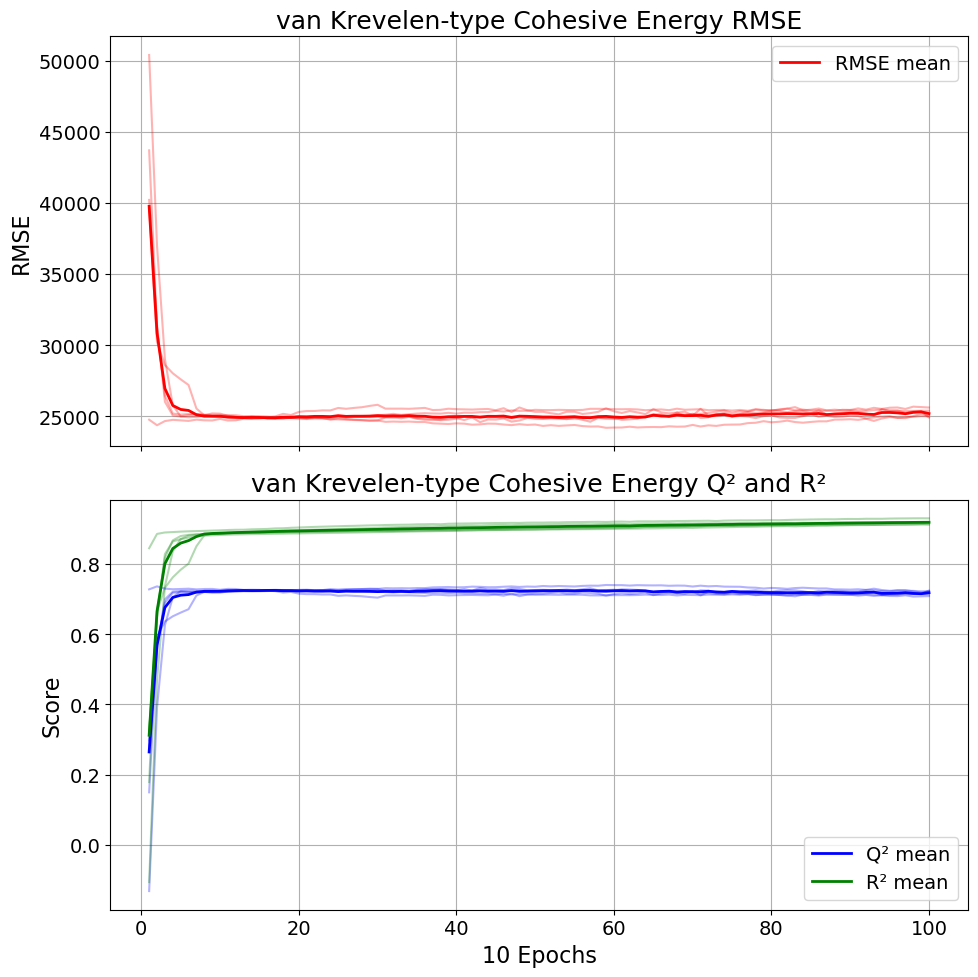

In [30]:
# Average across runs
q2_mean = q2_history.mean(axis=0)
rmse_mean = rmse_history.mean(axis=0)
r2_mean = r2_history.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('van Krevelen-type Cohesive Energy RMSE')
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('10 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('van Krevelen-type Cohesive Energy Q² and R²')
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

In [31]:
print(q2_mean[-1])
print(rmse_mean[-1])
print(r2_mean[-1])

0.7174199132160732
25184.066833057364
0.9179656185074332


## Fedors Cohesive Energy

In [32]:
X_fed = (
    data.dropna(subset=['E_coh_fedors'])
        [['chi0', 'chi1', 'chi0v_Si', 'chi1v_Si']]
)

y_fed = (
    data.dropna(subset=['E_coh_fedors'])
        [['E_coh_fedors']]
)

print(min(data.dropna(subset=['E_coh_fedors'])['E_coh_fedors']))
print(max(data.dropna(subset=['E_coh_fedors'])['E_coh_fedors']))

8290.0
242995.0


In [33]:
X_train, X_test, y_train, y_test = train_test_split(X_fed, y_fed, test_size = 0.2, random_state = 53)

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history = np.zeros((n_runs, n_iters))
rmse_history = np.zeros((n_runs, n_iters))
r2_history = np.zeros((n_runs, n_iters))
start_time = np.zeros(n_runs)
end_time = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train, y_train, epochs=100, verbose=0)

        # Predictions
        y_test_pred = model.predict(X_test).flatten()
        y_train_pred = model.predict(X_train).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history[run, i] = q2
        rmse_history[run, i] = rmse
        r2_history[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time[run] = time.time()
    print('total time:', end_time[run] - start_time[run])

Run 1/5
  Iter 0: Q²=-1.872, RMSE=77431.639, R²=-1.809
  Iter 1: Q²=-1.743, RMSE=75674.341, R²=-1.675
  Iter 2: Q²=-1.427, RMSE=71186.950, R²=-1.347
  Iter 3: Q²=-0.902, RMSE=63023.285, R²=-0.806
  Iter 4: Q²=-0.285, RMSE=51792.035, R²=-0.176
  Iter 5: Q²=0.266, RMSE=39145.181, R²=0.373
  Iter 6: Q²=0.636, RMSE=27569.150, R²=0.724
  Iter 7: Q²=0.809, RMSE=19954.001, R²=0.873
  Iter 8: Q²=0.864, RMSE=16863.734, R²=0.909
  Iter 9: Q²=0.877, RMSE=16018.148, R²=0.914
  Iter 10: Q²=0.880, RMSE=15827.384, R²=0.914
  Iter 11: Q²=0.881, RMSE=15786.221, R²=0.914
  Iter 12: Q²=0.881, RMSE=15765.615, R²=0.914
  Iter 13: Q²=0.881, RMSE=15762.438, R²=0.915
  Iter 14: Q²=0.881, RMSE=15757.805, R²=0.915
  Iter 15: Q²=0.881, RMSE=15734.629, R²=0.915
  Iter 16: Q²=0.881, RMSE=15744.225, R²=0.915
  Iter 17: Q²=0.882, RMSE=15705.469, R²=0.915
  Iter 18: Q²=0.883, RMSE=15655.215, R²=0.916
  Iter 19: Q²=0.882, RMSE=15711.175, R²=0.916
  Iter 20: Q²=0.883, RMSE=15639.848, R²=0.916
  Iter 21: Q²=0.883, RMSE=

  Iter 78: Q²=0.885, RMSE=15511.533, R²=0.921
  Iter 79: Q²=0.885, RMSE=15519.269, R²=0.921
  Iter 80: Q²=0.884, RMSE=15535.581, R²=0.921
  Iter 81: Q²=0.885, RMSE=15490.687, R²=0.921
  Iter 82: Q²=0.884, RMSE=15542.942, R²=0.921
  Iter 83: Q²=0.884, RMSE=15541.018, R²=0.921
  Iter 84: Q²=0.885, RMSE=15478.373, R²=0.921
  Iter 85: Q²=0.884, RMSE=15558.691, R²=0.921
  Iter 86: Q²=0.885, RMSE=15503.917, R²=0.921
  Iter 87: Q²=0.885, RMSE=15468.326, R²=0.921
  Iter 88: Q²=0.884, RMSE=15536.733, R²=0.921
  Iter 89: Q²=0.884, RMSE=15563.158, R²=0.921
  Iter 90: Q²=0.885, RMSE=15509.788, R²=0.921
  Iter 91: Q²=0.885, RMSE=15504.227, R²=0.921
  Iter 92: Q²=0.885, RMSE=15504.761, R²=0.921
  Iter 93: Q²=0.885, RMSE=15502.966, R²=0.921
  Iter 94: Q²=0.884, RMSE=15575.197, R²=0.921
  Iter 95: Q²=0.885, RMSE=15488.938, R²=0.921
  Iter 96: Q²=0.884, RMSE=15539.680, R²=0.921
  Iter 97: Q²=0.884, RMSE=15563.336, R²=0.921
  Iter 98: Q²=0.884, RMSE=15557.509, R²=0.921
  Iter 99: Q²=0.884, RMSE=15551.13

  Iter 55: Q²=0.885, RMSE=15514.670, R²=0.920
  Iter 56: Q²=0.884, RMSE=15534.108, R²=0.920
  Iter 57: Q²=0.886, RMSE=15461.607, R²=0.920
  Iter 58: Q²=0.885, RMSE=15529.181, R²=0.920
  Iter 59: Q²=0.885, RMSE=15481.529, R²=0.920
  Iter 60: Q²=0.885, RMSE=15492.588, R²=0.921
  Iter 61: Q²=0.885, RMSE=15514.921, R²=0.921
  Iter 62: Q²=0.885, RMSE=15501.471, R²=0.921
  Iter 63: Q²=0.885, RMSE=15491.400, R²=0.921
  Iter 64: Q²=0.885, RMSE=15516.052, R²=0.921
  Iter 65: Q²=0.885, RMSE=15500.014, R²=0.921
  Iter 66: Q²=0.885, RMSE=15503.613, R²=0.921
  Iter 67: Q²=0.885, RMSE=15499.723, R²=0.921
  Iter 68: Q²=0.885, RMSE=15515.009, R²=0.921
  Iter 69: Q²=0.884, RMSE=15535.333, R²=0.921
  Iter 70: Q²=0.885, RMSE=15476.023, R²=0.921
  Iter 71: Q²=0.885, RMSE=15501.659, R²=0.921
  Iter 72: Q²=0.885, RMSE=15491.774, R²=0.921
  Iter 73: Q²=0.884, RMSE=15531.207, R²=0.921
  Iter 74: Q²=0.885, RMSE=15511.313, R²=0.921
  Iter 75: Q²=0.885, RMSE=15525.059, R²=0.921
  Iter 76: Q²=0.884, RMSE=15544.16

In [34]:
end_time - start_time

array([35.84018254, 35.1303699 , 36.32897091, 35.51518893, 35.48721123])

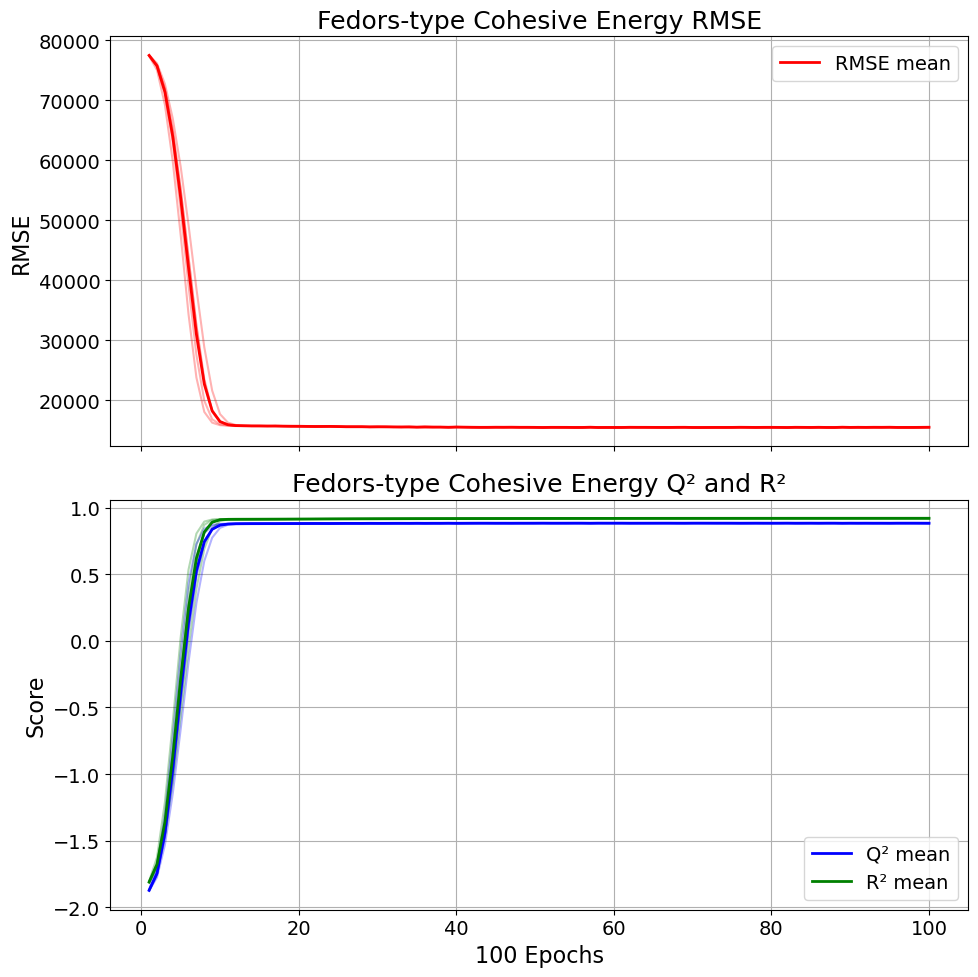

In [35]:
# Average across runs
q2_mean = q2_history.mean(axis=0)
rmse_mean = rmse_history.mean(axis=0)
r2_mean = r2_history.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('Fedors-type Cohesive Energy RMSE')
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('100 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('Fedors-type Cohesive Energy Q² and R²')
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

In [36]:
print(q2_mean[-1])
print(rmse_mean[-1])
print(r2_mean[-1])

0.8843842977308197
15537.045615094783
0.9214848564265937


### Use Scaled Data

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X_fed, y_fed, test_size = 0.2, random_state = 53)

X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
# y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history = np.zeros((n_runs, n_iters))
rmse_history = np.zeros((n_runs, n_iters))
r2_history = np.zeros((n_runs, n_iters))
start_time = np.zeros(n_runs)
end_time = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train_scaled.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train_scaled, y_train_scaled, epochs=100, verbose=0)

        # Predictions
        y_test_pred_scaled = model.predict(X_test_scaled)
        y_train_pred_scaled = model.predict(X_train_scaled)
        
        y_test_pred = y_scaler.inverse_transform(y_test_pred_scaled).flatten()
        y_train_pred = y_scaler.inverse_transform(y_train_pred_scaled).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history[run, i] = q2
        rmse_history[run, i] = rmse
        r2_history[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time[run] = time.time()
    print('total time:', end_time[run] - start_time[run])
    
print(end_time - start_time)

Run 1/5
  Iter 0: Q²=0.873, RMSE=16301.433, R²=0.919
  Iter 1: Q²=0.879, RMSE=15865.505, R²=0.924
  Iter 2: Q²=0.883, RMSE=15626.228, R²=0.928
  Iter 3: Q²=0.885, RMSE=15513.383, R²=0.932
  Iter 4: Q²=0.887, RMSE=15346.919, R²=0.935
  Iter 5: Q²=0.889, RMSE=15234.834, R²=0.938
  Iter 6: Q²=0.892, RMSE=15028.488, R²=0.940
  Iter 7: Q²=0.893, RMSE=14947.529, R²=0.942
  Iter 8: Q²=0.895, RMSE=14790.976, R²=0.945
  Iter 9: Q²=0.898, RMSE=14626.127, R²=0.947
  Iter 10: Q²=0.901, RMSE=14387.803, R²=0.949
  Iter 11: Q²=0.901, RMSE=14410.093, R²=0.951
  Iter 12: Q²=0.901, RMSE=14366.330, R²=0.953
  Iter 13: Q²=0.901, RMSE=14380.749, R²=0.955
  Iter 14: Q²=0.901, RMSE=14348.223, R²=0.957
  Iter 15: Q²=0.900, RMSE=14424.709, R²=0.958
  Iter 16: Q²=0.896, RMSE=14759.660, R²=0.960
  Iter 17: Q²=0.899, RMSE=14497.365, R²=0.961
  Iter 18: Q²=0.894, RMSE=14890.257, R²=0.962
  Iter 19: Q²=0.895, RMSE=14840.680, R²=0.963
  Iter 20: Q²=0.893, RMSE=14927.671, R²=0.965
  Iter 21: Q²=0.893, RMSE=14937.140,

  Iter 78: Q²=0.876, RMSE=16122.470, R²=0.975
  Iter 79: Q²=0.875, RMSE=16146.528, R²=0.975
  Iter 80: Q²=0.876, RMSE=16069.528, R²=0.975
  Iter 81: Q²=0.870, RMSE=16463.448, R²=0.975
  Iter 82: Q²=0.872, RMSE=16318.639, R²=0.975
  Iter 83: Q²=0.874, RMSE=16208.577, R²=0.976
  Iter 84: Q²=0.873, RMSE=16253.741, R²=0.976
  Iter 85: Q²=0.874, RMSE=16226.538, R²=0.976
  Iter 86: Q²=0.876, RMSE=16096.628, R²=0.976
  Iter 87: Q²=0.874, RMSE=16226.713, R²=0.976
  Iter 88: Q²=0.876, RMSE=16073.610, R²=0.976
  Iter 89: Q²=0.874, RMSE=16232.767, R²=0.976
  Iter 90: Q²=0.873, RMSE=16314.311, R²=0.976
  Iter 91: Q²=0.871, RMSE=16401.574, R²=0.976
  Iter 92: Q²=0.874, RMSE=16225.953, R²=0.976
  Iter 93: Q²=0.871, RMSE=16408.445, R²=0.976
  Iter 94: Q²=0.872, RMSE=16358.076, R²=0.976
  Iter 95: Q²=0.871, RMSE=16396.360, R²=0.976
  Iter 96: Q²=0.871, RMSE=16439.084, R²=0.977
  Iter 97: Q²=0.869, RMSE=16530.908, R²=0.976
  Iter 98: Q²=0.868, RMSE=16616.013, R²=0.977
  Iter 99: Q²=0.869, RMSE=16542.88

  Iter 55: Q²=0.855, RMSE=17370.453, R²=0.973
  Iter 56: Q²=0.852, RMSE=17557.450, R²=0.974
  Iter 57: Q²=0.852, RMSE=17583.011, R²=0.974
  Iter 58: Q²=0.848, RMSE=17794.208, R²=0.973
  Iter 59: Q²=0.854, RMSE=17458.621, R²=0.974
  Iter 60: Q²=0.852, RMSE=17559.827, R²=0.974
  Iter 61: Q²=0.850, RMSE=17681.250, R²=0.974
  Iter 62: Q²=0.854, RMSE=17451.938, R²=0.974
  Iter 63: Q²=0.846, RMSE=17918.885, R²=0.974
  Iter 64: Q²=0.856, RMSE=17360.358, R²=0.974
  Iter 65: Q²=0.854, RMSE=17431.423, R²=0.974
  Iter 66: Q²=0.848, RMSE=17803.156, R²=0.974
  Iter 67: Q²=0.848, RMSE=17798.214, R²=0.974
  Iter 68: Q²=0.849, RMSE=17746.018, R²=0.974
  Iter 69: Q²=0.849, RMSE=17745.885, R²=0.974
  Iter 70: Q²=0.844, RMSE=18064.131, R²=0.974
  Iter 71: Q²=0.846, RMSE=17950.362, R²=0.974
  Iter 72: Q²=0.847, RMSE=17894.813, R²=0.975
  Iter 73: Q²=0.851, RMSE=17659.312, R²=0.975
  Iter 74: Q²=0.851, RMSE=17609.060, R²=0.975
  Iter 75: Q²=0.852, RMSE=17566.460, R²=0.975
  Iter 76: Q²=0.850, RMSE=17707.15

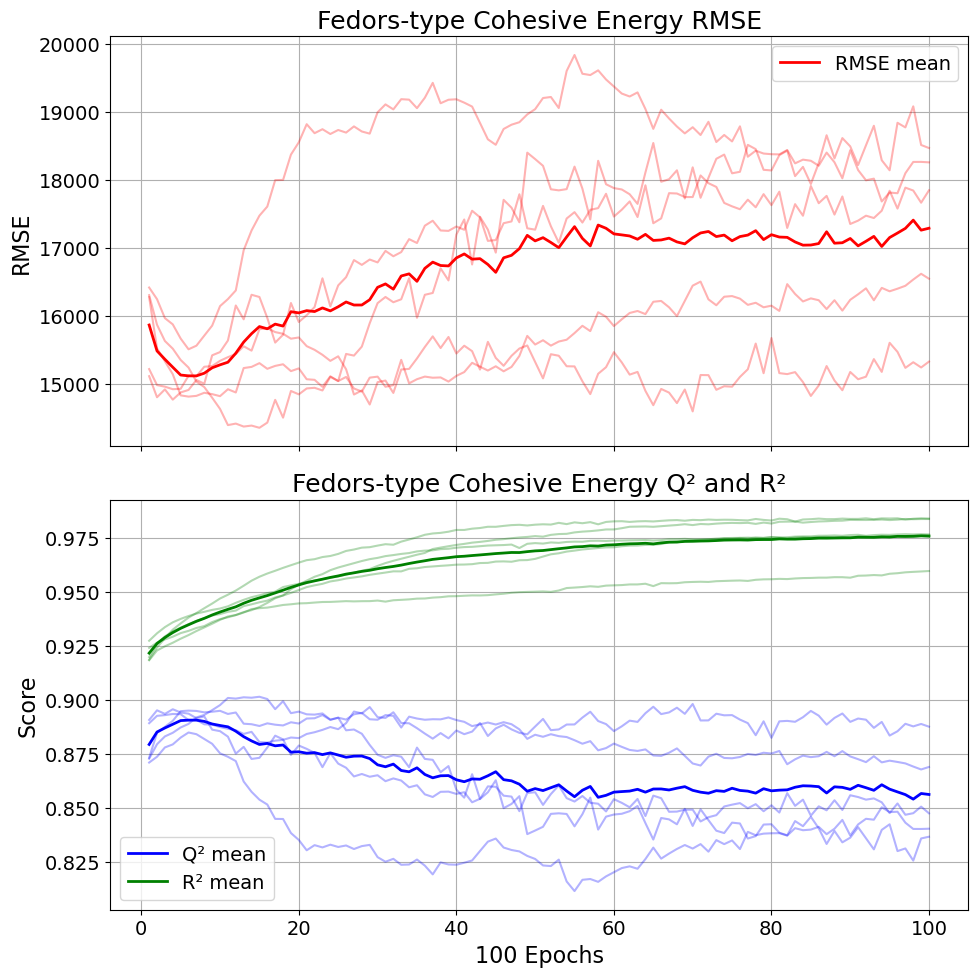

In [38]:
# Average across runs
q2_mean = q2_history.mean(axis=0)
rmse_mean = rmse_history.mean(axis=0)
r2_mean = r2_history.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('Fedors-type Cohesive Energy RMSE')
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('100 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('Fedors-type Cohesive Energy Q² and R²')
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

In [39]:
print(q2_mean[-1])
print(rmse_mean[-1])
print(r2_mean[-1])

0.856196336681687
17287.084973713896
0.9757668457671196


### Zoom in on early Epochs

In [40]:
X_train, X_test, y_train, y_test = train_test_split(X_fed, y_fed, test_size = 0.2, random_state = 53)

X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
# y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history = np.zeros((n_runs, n_iters))
rmse_history = np.zeros((n_runs, n_iters))
r2_history = np.zeros((n_runs, n_iters))
start_time = np.zeros(n_runs)
end_time = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train_scaled.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train_scaled, y_train_scaled, epochs=20, verbose=0)

        # Predictions
        y_test_pred_scaled = model.predict(X_test_scaled)
        y_train_pred_scaled = model.predict(X_train_scaled)
        
        y_test_pred = y_scaler.inverse_transform(y_test_pred_scaled).flatten()
        y_train_pred = y_scaler.inverse_transform(y_train_pred_scaled).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history[run, i] = q2
        rmse_history[run, i] = rmse
        r2_history[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time[run] = time.time()
    print('total time:', end_time[run] - start_time[run])
    
print(end_time - start_time)

Run 1/5
  Iter 0: Q²=0.763, RMSE=22239.332, R²=0.737
  Iter 1: Q²=0.813, RMSE=19762.417, R²=0.822
  Iter 2: Q²=0.847, RMSE=17888.633, R²=0.873
  Iter 3: Q²=0.862, RMSE=17002.178, R²=0.903
  Iter 4: Q²=0.880, RMSE=15815.334, R²=0.917
  Iter 5: Q²=0.885, RMSE=15523.565, R²=0.920
  Iter 6: Q²=0.883, RMSE=15614.974, R²=0.921
  Iter 7: Q²=0.884, RMSE=15533.307, R²=0.922
  Iter 8: Q²=0.886, RMSE=15405.842, R²=0.923
  Iter 9: Q²=0.886, RMSE=15440.377, R²=0.924
  Iter 10: Q²=0.885, RMSE=15468.511, R²=0.924
  Iter 11: Q²=0.886, RMSE=15433.972, R²=0.925
  Iter 12: Q²=0.886, RMSE=15405.923, R²=0.927
  Iter 13: Q²=0.888, RMSE=15290.992, R²=0.928
  Iter 14: Q²=0.886, RMSE=15400.966, R²=0.928
  Iter 15: Q²=0.888, RMSE=15300.737, R²=0.929
  Iter 16: Q²=0.886, RMSE=15426.620, R²=0.930
  Iter 17: Q²=0.887, RMSE=15363.827, R²=0.930
  Iter 18: Q²=0.886, RMSE=15413.696, R²=0.930
  Iter 19: Q²=0.885, RMSE=15500.771, R²=0.931
  Iter 20: Q²=0.889, RMSE=15252.498, R²=0.931
  Iter 21: Q²=0.887, RMSE=15337.743,

  Iter 78: Q²=0.867, RMSE=16647.973, R²=0.961
  Iter 79: Q²=0.869, RMSE=16539.618, R²=0.961
  Iter 80: Q²=0.869, RMSE=16542.838, R²=0.961
  Iter 81: Q²=0.871, RMSE=16408.531, R²=0.962
  Iter 82: Q²=0.867, RMSE=16667.508, R²=0.962
  Iter 83: Q²=0.868, RMSE=16603.357, R²=0.962
  Iter 84: Q²=0.869, RMSE=16533.850, R²=0.962
  Iter 85: Q²=0.870, RMSE=16474.016, R²=0.963
  Iter 86: Q²=0.865, RMSE=16764.936, R²=0.963
  Iter 87: Q²=0.867, RMSE=16675.031, R²=0.963
  Iter 88: Q²=0.866, RMSE=16751.327, R²=0.964
  Iter 89: Q²=0.865, RMSE=16765.823, R²=0.964
  Iter 90: Q²=0.866, RMSE=16725.312, R²=0.964
  Iter 91: Q²=0.869, RMSE=16533.586, R²=0.964
  Iter 92: Q²=0.864, RMSE=16881.935, R²=0.965
  Iter 93: Q²=0.864, RMSE=16847.708, R²=0.965
  Iter 94: Q²=0.865, RMSE=16770.423, R²=0.965
  Iter 95: Q²=0.868, RMSE=16617.334, R²=0.965
  Iter 96: Q²=0.871, RMSE=16380.252, R²=0.965
  Iter 97: Q²=0.867, RMSE=16688.892, R²=0.966
  Iter 98: Q²=0.866, RMSE=16744.125, R²=0.966
  Iter 99: Q²=0.864, RMSE=16861.36

  Iter 56: Q²=0.894, RMSE=14851.705, R²=0.943
  Iter 57: Q²=0.897, RMSE=14634.134, R²=0.943
  Iter 58: Q²=0.895, RMSE=14773.614, R²=0.943
  Iter 59: Q²=0.896, RMSE=14714.954, R²=0.943
  Iter 60: Q²=0.895, RMSE=14834.459, R²=0.943
  Iter 61: Q²=0.896, RMSE=14737.344, R²=0.943
  Iter 62: Q²=0.895, RMSE=14822.412, R²=0.943
  Iter 63: Q²=0.896, RMSE=14733.074, R²=0.944
  Iter 64: Q²=0.895, RMSE=14817.660, R²=0.944
  Iter 65: Q²=0.896, RMSE=14741.973, R²=0.944
  Iter 66: Q²=0.897, RMSE=14647.784, R²=0.944
  Iter 67: Q²=0.894, RMSE=14845.820, R²=0.944
  Iter 68: Q²=0.897, RMSE=14658.761, R²=0.944
  Iter 69: Q²=0.895, RMSE=14824.280, R²=0.944
  Iter 70: Q²=0.898, RMSE=14616.758, R²=0.945
  Iter 71: Q²=0.897, RMSE=14675.548, R²=0.945
  Iter 72: Q²=0.898, RMSE=14628.230, R²=0.945
  Iter 73: Q²=0.895, RMSE=14822.751, R²=0.945
  Iter 74: Q²=0.896, RMSE=14756.544, R²=0.945
  Iter 75: Q²=0.898, RMSE=14610.148, R²=0.945
  Iter 76: Q²=0.897, RMSE=14699.922, R²=0.946
  Iter 77: Q²=0.899, RMSE=14540.44

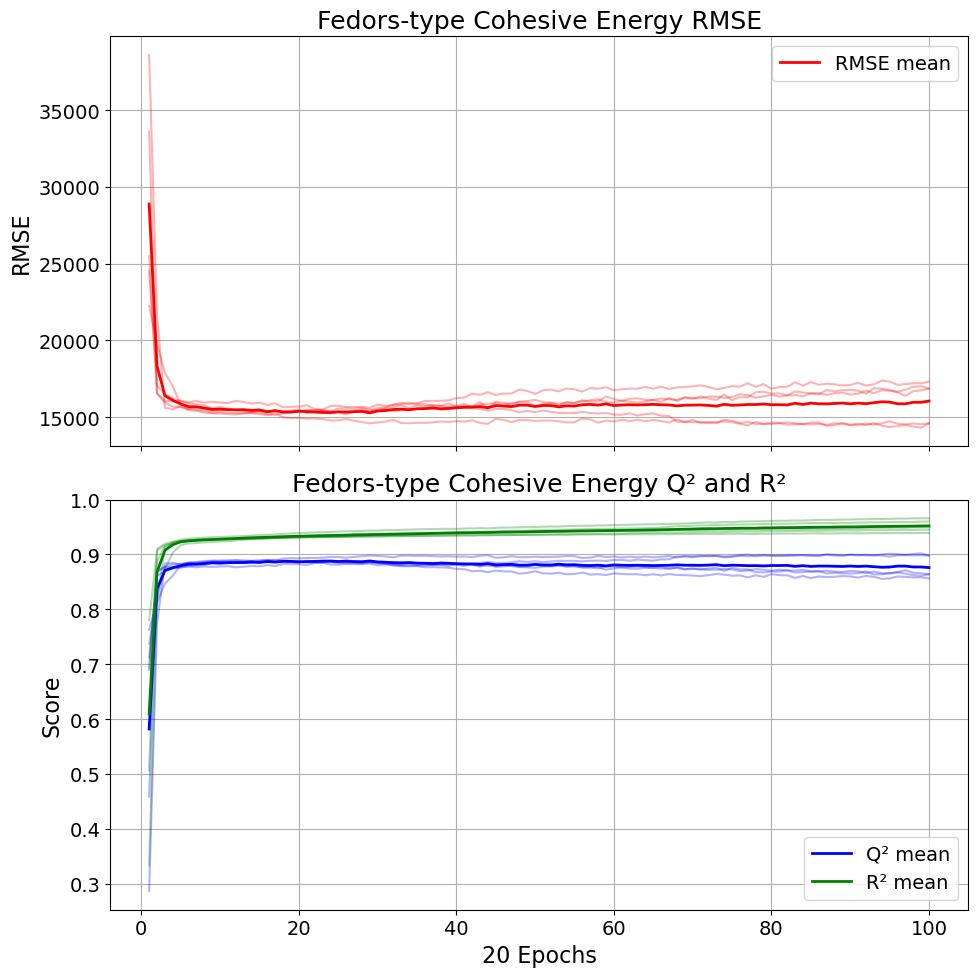

In [41]:
# Average across runs
q2_mean = q2_history.mean(axis=0)
rmse_mean = rmse_history.mean(axis=0)
r2_mean = r2_history.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('Fedors-type Cohesive Energy RMSE')
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('20 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('Fedors-type Cohesive Energy Q² and R²')
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

In [42]:
print(q2_mean[-1])
print(rmse_mean[-1])
print(r2_mean[-1])

0.8760248061201257
16044.623433233539
0.9521276210529462


## Molar Volume

In [43]:
X_mv = (
    data.dropna(subset=['molar_volume'])
        [['chi0', 'chi1', 'chi0v_Si', 'chi1v_Si']]
)

y_mv = (
    data.dropna(subset=['molar_volume'])
        [['molar_volume']]
)

print(min(data.dropna(subset=['molar_volume'])['molar_volume']))
print(max(data.dropna(subset=['molar_volume'])['molar_volume']))

24.0
466.6


In [44]:
X_train, X_test, y_train, y_test = train_test_split(X_mv, y_mv, test_size = 0.2, random_state = 53)

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history = np.zeros((n_runs, n_iters))
rmse_history = np.zeros((n_runs, n_iters))
r2_history = np.zeros((n_runs, n_iters))
start_time = np.zeros(n_runs)
end_time = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train, y_train, epochs=100, verbose=0)

        # Predictions
        y_test_pred = model.predict(X_test).flatten()
        y_train_pred = model.predict(X_train).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history[run, i] = q2
        rmse_history[run, i] = rmse
        r2_history[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time[run] = time.time()
    print('total time:', end_time[run] - start_time[run])

Run 1/5
  Iter 0: Q²=0.932, RMSE=18.301, R²=0.903
  Iter 1: Q²=0.940, RMSE=17.160, R²=0.927
  Iter 2: Q²=0.940, RMSE=17.128, R²=0.927
  Iter 3: Q²=0.941, RMSE=16.934, R²=0.928
  Iter 4: Q²=0.942, RMSE=16.839, R²=0.928
  Iter 5: Q²=0.945, RMSE=16.475, R²=0.929
  Iter 6: Q²=0.946, RMSE=16.297, R²=0.930
  Iter 7: Q²=0.948, RMSE=15.930, R²=0.930
  Iter 8: Q²=0.950, RMSE=15.657, R²=0.931
  Iter 9: Q²=0.951, RMSE=15.491, R²=0.932
  Iter 10: Q²=0.954, RMSE=15.088, R²=0.933
  Iter 11: Q²=0.955, RMSE=14.822, R²=0.933
  Iter 12: Q²=0.956, RMSE=14.711, R²=0.934
  Iter 13: Q²=0.957, RMSE=14.438, R²=0.934
  Iter 14: Q²=0.959, RMSE=14.126, R²=0.935
  Iter 15: Q²=0.961, RMSE=13.875, R²=0.935
  Iter 16: Q²=0.961, RMSE=13.837, R²=0.936
  Iter 17: Q²=0.963, RMSE=13.437, R²=0.936
  Iter 18: Q²=0.964, RMSE=13.273, R²=0.937
  Iter 19: Q²=0.965, RMSE=13.158, R²=0.937
  Iter 20: Q²=0.966, RMSE=12.928, R²=0.937
  Iter 21: Q²=0.966, RMSE=12.914, R²=0.938
  Iter 22: Q²=0.967, RMSE=12.748, R²=0.938
  Iter 23: Q²

  Iter 90: Q²=0.967, RMSE=12.697, R²=0.948
  Iter 91: Q²=0.967, RMSE=12.631, R²=0.948
  Iter 92: Q²=0.967, RMSE=12.637, R²=0.948
  Iter 93: Q²=0.968, RMSE=12.599, R²=0.948
  Iter 94: Q²=0.968, RMSE=12.486, R²=0.948
  Iter 95: Q²=0.968, RMSE=12.561, R²=0.948
  Iter 96: Q²=0.965, RMSE=13.028, R²=0.948
  Iter 97: Q²=0.968, RMSE=12.569, R²=0.948
  Iter 98: Q²=0.968, RMSE=12.482, R²=0.948
  Iter 99: Q²=0.968, RMSE=12.479, R²=0.948
total time: 37.848238945007324
Run 3/5
  Iter 0: Q²=0.936, RMSE=17.757, R²=0.924
  Iter 1: Q²=0.937, RMSE=17.626, R²=0.924
  Iter 2: Q²=0.938, RMSE=17.438, R²=0.925
  Iter 3: Q²=0.940, RMSE=17.143, R²=0.926
  Iter 4: Q²=0.941, RMSE=16.946, R²=0.927
  Iter 5: Q²=0.943, RMSE=16.689, R²=0.928
  Iter 6: Q²=0.946, RMSE=16.303, R²=0.929
  Iter 7: Q²=0.948, RMSE=15.992, R²=0.930
  Iter 8: Q²=0.949, RMSE=15.814, R²=0.931
  Iter 9: Q²=0.952, RMSE=15.273, R²=0.932
  Iter 10: Q²=0.955, RMSE=14.921, R²=0.933
  Iter 11: Q²=0.957, RMSE=14.525, R²=0.933
  Iter 12: Q²=0.958, RMSE

  Iter 80: Q²=0.963, RMSE=13.413, R²=0.945
  Iter 81: Q²=0.963, RMSE=13.465, R²=0.945
  Iter 82: Q²=0.963, RMSE=13.395, R²=0.945
  Iter 83: Q²=0.962, RMSE=13.568, R²=0.945
  Iter 84: Q²=0.964, RMSE=13.334, R²=0.945
  Iter 85: Q²=0.964, RMSE=13.215, R²=0.945
  Iter 86: Q²=0.963, RMSE=13.405, R²=0.945
  Iter 87: Q²=0.964, RMSE=13.350, R²=0.945
  Iter 88: Q²=0.964, RMSE=13.236, R²=0.945
  Iter 89: Q²=0.964, RMSE=13.303, R²=0.945
  Iter 90: Q²=0.964, RMSE=13.359, R²=0.945
  Iter 91: Q²=0.964, RMSE=13.353, R²=0.945
  Iter 92: Q²=0.963, RMSE=13.443, R²=0.945
  Iter 93: Q²=0.964, RMSE=13.315, R²=0.945
  Iter 94: Q²=0.962, RMSE=13.571, R²=0.945
  Iter 95: Q²=0.964, RMSE=13.300, R²=0.945
  Iter 96: Q²=0.963, RMSE=13.516, R²=0.945
  Iter 97: Q²=0.965, RMSE=13.137, R²=0.945
  Iter 98: Q²=0.964, RMSE=13.239, R²=0.945
  Iter 99: Q²=0.963, RMSE=13.523, R²=0.945
total time: 35.58417773246765
Run 5/5
  Iter 0: Q²=0.941, RMSE=17.018, R²=0.911
  Iter 1: Q²=0.941, RMSE=16.939, R²=0.925
  Iter 2: Q²=0.942

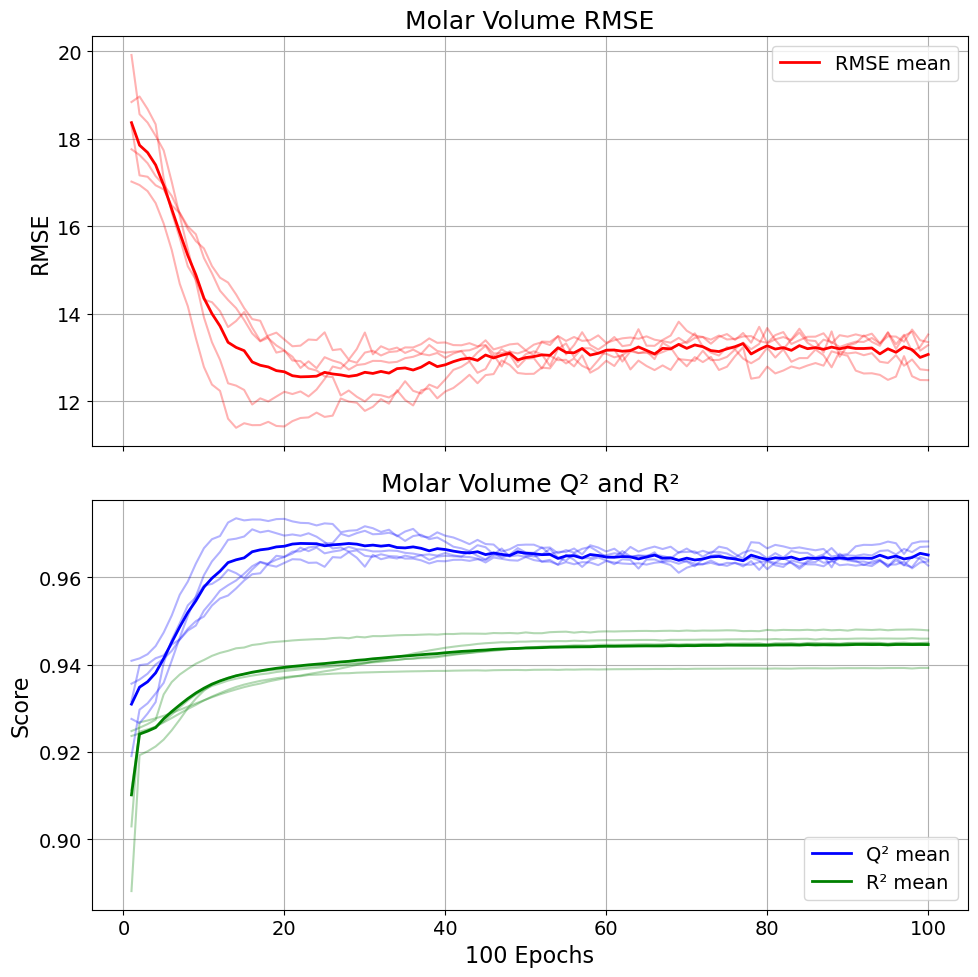

In [45]:
# Average across runs
q2_mean = q2_history.mean(axis=0)
rmse_mean = rmse_history.mean(axis=0)
r2_mean = r2_history.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('Molar Volume RMSE')
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('100 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('Molar Volume Q² and R²')
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

In [46]:
print(q2_mean[-1])
print(rmse_mean[-1])
print(r2_mean[-1])

0.9651066484226384
13.067537916465463
0.9445844543064659


### Using Scaled Data

In [48]:
X_train, X_test, y_train, y_test = train_test_split(X_mv, y_mv, test_size = 0.2, random_state = 53)

X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
# y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history = np.zeros((n_runs, n_iters))
rmse_history = np.zeros((n_runs, n_iters))
r2_history = np.zeros((n_runs, n_iters))
start_time = np.zeros(n_runs)
end_time = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train_scaled.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train_scaled, y_train_scaled, epochs=100, verbose=0)

        # Predictions
        y_test_pred_scaled = model.predict(X_test_scaled)
        y_train_pred_scaled = model.predict(X_train_scaled)
        
        y_test_pred = y_scaler.inverse_transform(y_test_pred_scaled).flatten()
        y_train_pred = y_scaler.inverse_transform(y_train_pred_scaled).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history[run, i] = q2
        rmse_history[run, i] = rmse
        r2_history[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time[run] = time.time()
    print('total time:', end_time[run] - start_time[run])
    
print(end_time - start_time)

Run 1/5
  Iter 0: Q²=0.965, RMSE=13.077, R²=0.945
  Iter 1: Q²=0.963, RMSE=13.398, R²=0.948
  Iter 2: Q²=0.961, RMSE=13.788, R²=0.949
  Iter 3: Q²=0.960, RMSE=13.977, R²=0.950
  Iter 4: Q²=0.961, RMSE=13.842, R²=0.951
  Iter 5: Q²=0.961, RMSE=13.892, R²=0.951
  Iter 6: Q²=0.960, RMSE=14.067, R²=0.952
  Iter 7: Q²=0.959, RMSE=14.095, R²=0.952
  Iter 8: Q²=0.959, RMSE=14.117, R²=0.952
  Iter 9: Q²=0.959, RMSE=14.129, R²=0.953
  Iter 10: Q²=0.961, RMSE=13.766, R²=0.953
  Iter 11: Q²=0.958, RMSE=14.414, R²=0.953
  Iter 12: Q²=0.957, RMSE=14.540, R²=0.953
  Iter 13: Q²=0.954, RMSE=15.057, R²=0.954
  Iter 14: Q²=0.960, RMSE=13.986, R²=0.955
  Iter 15: Q²=0.961, RMSE=13.856, R²=0.955
  Iter 16: Q²=0.959, RMSE=14.167, R²=0.955
  Iter 17: Q²=0.958, RMSE=14.315, R²=0.956
  Iter 18: Q²=0.957, RMSE=14.512, R²=0.956
  Iter 19: Q²=0.954, RMSE=15.001, R²=0.957
  Iter 20: Q²=0.951, RMSE=15.477, R²=0.957
  Iter 21: Q²=0.953, RMSE=15.191, R²=0.958
  Iter 22: Q²=0.952, RMSE=15.391, R²=0.958
  Iter 23: Q²

  Iter 90: Q²=0.941, RMSE=17.044, R²=0.989
  Iter 91: Q²=0.941, RMSE=16.928, R²=0.989
  Iter 92: Q²=0.941, RMSE=17.009, R²=0.989
  Iter 93: Q²=0.943, RMSE=16.687, R²=0.989
  Iter 94: Q²=0.945, RMSE=16.405, R²=0.989
  Iter 95: Q²=0.942, RMSE=16.786, R²=0.989
  Iter 96: Q²=0.949, RMSE=15.850, R²=0.989
  Iter 97: Q²=0.951, RMSE=15.517, R²=0.989
  Iter 98: Q²=0.949, RMSE=15.809, R²=0.989
  Iter 99: Q²=0.950, RMSE=15.676, R²=0.989
total time: 33.34866499900818
Run 3/5
  Iter 0: Q²=0.947, RMSE=16.176, R²=0.938
  Iter 1: Q²=0.954, RMSE=14.949, R²=0.942
  Iter 2: Q²=0.961, RMSE=13.820, R²=0.945
  Iter 3: Q²=0.962, RMSE=13.622, R²=0.947
  Iter 4: Q²=0.962, RMSE=13.609, R²=0.948
  Iter 5: Q²=0.960, RMSE=13.981, R²=0.950
  Iter 6: Q²=0.961, RMSE=13.900, R²=0.950
  Iter 7: Q²=0.963, RMSE=13.514, R²=0.951
  Iter 8: Q²=0.960, RMSE=13.927, R²=0.952
  Iter 9: Q²=0.957, RMSE=14.480, R²=0.953
  Iter 10: Q²=0.958, RMSE=14.291, R²=0.953
  Iter 11: Q²=0.958, RMSE=14.396, R²=0.954
  Iter 12: Q²=0.958, RMSE=

  Iter 80: Q²=0.761, RMSE=34.207, R²=0.988
  Iter 81: Q²=0.761, RMSE=34.220, R²=0.988
  Iter 82: Q²=0.765, RMSE=33.947, R²=0.988
  Iter 83: Q²=0.763, RMSE=34.101, R²=0.988
  Iter 84: Q²=0.763, RMSE=34.079, R²=0.988
  Iter 85: Q²=0.762, RMSE=34.176, R²=0.988
  Iter 86: Q²=0.764, RMSE=34.013, R²=0.988
  Iter 87: Q²=0.762, RMSE=34.167, R²=0.988
  Iter 88: Q²=0.765, RMSE=33.943, R²=0.988
  Iter 89: Q²=0.765, RMSE=33.893, R²=0.988
  Iter 90: Q²=0.764, RMSE=34.031, R²=0.988
  Iter 91: Q²=0.763, RMSE=34.041, R²=0.988
  Iter 92: Q²=0.766, RMSE=33.876, R²=0.988
  Iter 93: Q²=0.771, RMSE=33.465, R²=0.988
  Iter 94: Q²=0.770, RMSE=33.589, R²=0.988
  Iter 95: Q²=0.770, RMSE=33.579, R²=0.988
  Iter 96: Q²=0.769, RMSE=33.645, R²=0.988
  Iter 97: Q²=0.770, RMSE=33.555, R²=0.988
  Iter 98: Q²=0.767, RMSE=33.779, R²=0.988
  Iter 99: Q²=0.769, RMSE=33.622, R²=0.988
total time: 33.88709616661072
Run 5/5
  Iter 0: Q²=0.927, RMSE=18.861, R²=0.934
  Iter 1: Q²=0.944, RMSE=16.523, R²=0.946
  Iter 2: Q²=0.955

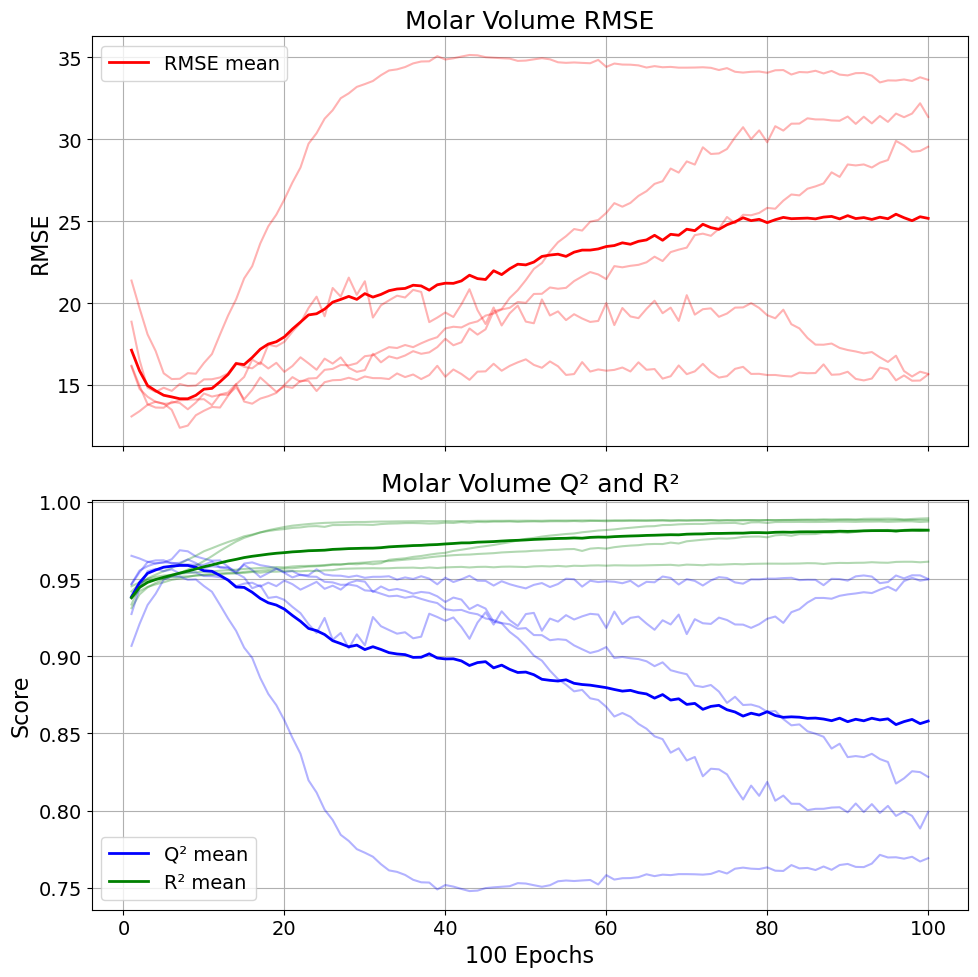

In [49]:
# Average across runs
q2_mean = q2_history.mean(axis=0)
rmse_mean = rmse_history.mean(axis=0)
r2_mean = r2_history.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('Molar Volume RMSE')
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('100 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('Molar Volume Q² and R²')
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

In [50]:
print(q2_mean[-1])
print(rmse_mean[-1])
print(r2_mean[-1])

0.8580427377186857
25.16743647070003
0.9816428260594471


### Zoom in on early Epochs

In [51]:
X_train, X_test, y_train, y_test = train_test_split(X_mv, y_mv, test_size = 0.2, random_state = 53)

X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
# y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history = np.zeros((n_runs, n_iters))
rmse_history = np.zeros((n_runs, n_iters))
r2_history = np.zeros((n_runs, n_iters))
start_time = np.zeros(n_runs)
end_time = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train_scaled.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train_scaled, y_train_scaled, epochs=10, verbose=0)

        # Predictions
        y_test_pred_scaled = model.predict(X_test_scaled)
        y_train_pred_scaled = model.predict(X_train_scaled)
        
        y_test_pred = y_scaler.inverse_transform(y_test_pred_scaled).flatten()
        y_train_pred = y_scaler.inverse_transform(y_train_pred_scaled).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history[run, i] = q2
        rmse_history[run, i] = rmse
        r2_history[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time[run] = time.time()
    print('total time:', end_time[run] - start_time[run])
    
print(end_time - start_time)

Run 1/5
  Iter 0: Q²=0.911, RMSE=20.869, R²=0.906
  Iter 1: Q²=0.925, RMSE=19.144, R²=0.928
  Iter 2: Q²=0.937, RMSE=17.581, R²=0.935
  Iter 3: Q²=0.944, RMSE=16.491, R²=0.939
  Iter 4: Q²=0.948, RMSE=16.004, R²=0.941
  Iter 5: Q²=0.952, RMSE=15.304, R²=0.943
  Iter 6: Q²=0.953, RMSE=15.151, R²=0.944
  Iter 7: Q²=0.954, RMSE=15.012, R²=0.945
  Iter 8: Q²=0.957, RMSE=14.571, R²=0.946
  Iter 9: Q²=0.957, RMSE=14.493, R²=0.946
  Iter 10: Q²=0.959, RMSE=14.196, R²=0.947
  Iter 11: Q²=0.960, RMSE=13.910, R²=0.947
  Iter 12: Q²=0.960, RMSE=13.969, R²=0.948
  Iter 13: Q²=0.962, RMSE=13.723, R²=0.948
  Iter 14: Q²=0.959, RMSE=14.170, R²=0.948
  Iter 15: Q²=0.962, RMSE=13.624, R²=0.949
  Iter 16: Q²=0.961, RMSE=13.880, R²=0.949
  Iter 17: Q²=0.960, RMSE=14.072, R²=0.949
  Iter 18: Q²=0.960, RMSE=13.969, R²=0.949
  Iter 19: Q²=0.961, RMSE=13.822, R²=0.950
  Iter 20: Q²=0.961, RMSE=13.734, R²=0.950
  Iter 21: Q²=0.961, RMSE=13.864, R²=0.950
  Iter 22: Q²=0.961, RMSE=13.891, R²=0.950
  Iter 23: Q²

  Iter 91: Q²=0.959, RMSE=14.251, R²=0.957
  Iter 92: Q²=0.958, RMSE=14.369, R²=0.957
  Iter 93: Q²=0.959, RMSE=14.088, R²=0.957
  Iter 94: Q²=0.959, RMSE=14.206, R²=0.957
  Iter 95: Q²=0.961, RMSE=13.894, R²=0.957
  Iter 96: Q²=0.959, RMSE=14.210, R²=0.957
  Iter 97: Q²=0.957, RMSE=14.502, R²=0.957
  Iter 98: Q²=0.960, RMSE=13.941, R²=0.958
  Iter 99: Q²=0.959, RMSE=14.156, R²=0.958
total time: 12.260393857955933
Run 3/5
  Iter 0: Q²=-0.023, RMSE=70.802, R²=-0.077
  Iter 1: Q²=0.514, RMSE=48.802, R²=0.488
  Iter 2: Q²=0.717, RMSE=37.254, R²=0.739
  Iter 3: Q²=0.815, RMSE=30.093, R²=0.839
  Iter 4: Q²=0.873, RMSE=24.936, R²=0.890
  Iter 5: Q²=0.903, RMSE=21.751, R²=0.914
  Iter 6: Q²=0.922, RMSE=19.586, R²=0.924
  Iter 7: Q²=0.933, RMSE=18.112, R²=0.930
  Iter 8: Q²=0.939, RMSE=17.272, R²=0.933
  Iter 9: Q²=0.943, RMSE=16.752, R²=0.935
  Iter 10: Q²=0.944, RMSE=16.538, R²=0.936
  Iter 11: Q²=0.948, RMSE=15.982, R²=0.938
  Iter 12: Q²=0.950, RMSE=15.590, R²=0.939
  Iter 13: Q²=0.954, RM

  Iter 82: Q²=0.959, RMSE=14.182, R²=0.951
  Iter 83: Q²=0.958, RMSE=14.338, R²=0.951
  Iter 84: Q²=0.958, RMSE=14.350, R²=0.951
  Iter 85: Q²=0.959, RMSE=14.161, R²=0.951
  Iter 86: Q²=0.960, RMSE=14.064, R²=0.951
  Iter 87: Q²=0.959, RMSE=14.235, R²=0.951
  Iter 88: Q²=0.959, RMSE=14.141, R²=0.951
  Iter 89: Q²=0.959, RMSE=14.134, R²=0.951
  Iter 90: Q²=0.960, RMSE=14.082, R²=0.951
  Iter 91: Q²=0.958, RMSE=14.319, R²=0.951
  Iter 92: Q²=0.958, RMSE=14.276, R²=0.951
  Iter 93: Q²=0.959, RMSE=14.101, R²=0.951
  Iter 94: Q²=0.960, RMSE=14.063, R²=0.952
  Iter 95: Q²=0.959, RMSE=14.163, R²=0.952
  Iter 96: Q²=0.959, RMSE=14.108, R²=0.952
  Iter 97: Q²=0.959, RMSE=14.238, R²=0.952
  Iter 98: Q²=0.959, RMSE=14.090, R²=0.952
  Iter 99: Q²=0.959, RMSE=14.105, R²=0.952
total time: 12.017040967941284
Run 5/5
  Iter 0: Q²=0.837, RMSE=28.289, R²=0.833
  Iter 1: Q²=0.943, RMSE=16.682, R²=0.927
  Iter 2: Q²=0.954, RMSE=15.064, R²=0.938
  Iter 3: Q²=0.958, RMSE=14.314, R²=0.941
  Iter 4: Q²=0.961,

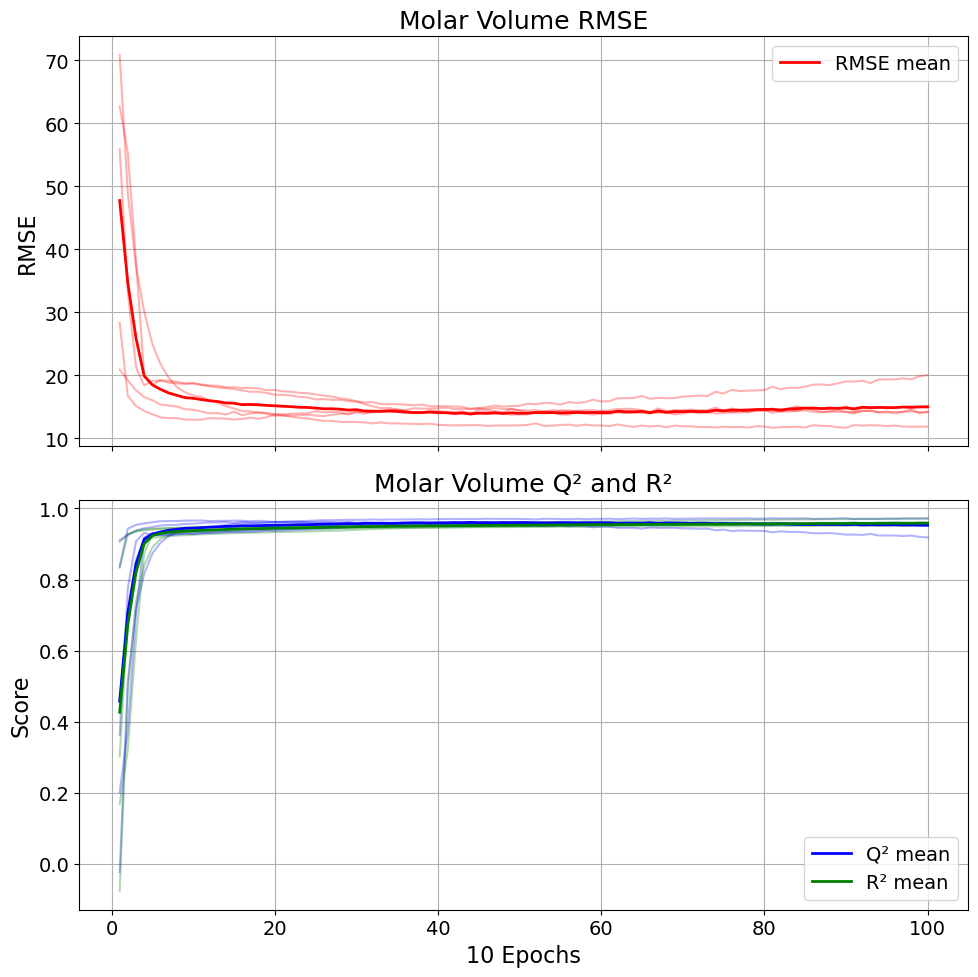

In [52]:
# Average across runs
q2_mean = q2_history.mean(axis=0)
rmse_mean = rmse_history.mean(axis=0)
r2_mean = r2_history.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('Molar Volume RMSE')
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('10 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('Molar Volume Q² and R²')
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

In [53]:
print(q2_mean[-1])
print(rmse_mean[-1])
print(r2_mean[-1])

0.9527505908820857
14.970202326988561
0.958749106667742


## Glass Transition Temperature

In [54]:
X_gtt = gtt_data.drop(columns = ['Tg(exp)(K)', 'Tg(fit)(K)'])

y_gtt = gtt_data['Tg(exp)(K)']

print(min(gtt_data.dropna(subset=['Tg(exp)(K)'])['Tg(exp)(K)']))
print(max(gtt_data.dropna(subset=['Tg(exp)(K)'])['Tg(exp)(K)']))

130
685


In [55]:
X_train, X_test, y_train, y_test = train_test_split(X_gtt, y_gtt, test_size = 0.2, random_state = 53)

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history = np.zeros((n_runs, n_iters))
rmse_history = np.zeros((n_runs, n_iters))
r2_history = np.zeros((n_runs, n_iters))
start_time = np.zeros(n_runs)
end_time = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train, y_train, epochs=100, verbose=0)

        # Predictions
        y_test_pred = model.predict(X_test).flatten()
        y_train_pred = model.predict(X_train).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history[run, i] = q2
        rmse_history[run, i] = rmse
        r2_history[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time[run] = time.time()
    print('total time:', end_time[run] - start_time[run])

Run 1/5
  Iter 0: Q²=0.561, RMSE=84.956, R²=0.538
  Iter 1: Q²=0.797, RMSE=57.801, R²=0.779
  Iter 2: Q²=0.815, RMSE=55.104, R²=0.800
  Iter 3: Q²=0.826, RMSE=53.538, R²=0.813
  Iter 4: Q²=0.839, RMSE=51.497, R²=0.829
  Iter 5: Q²=0.847, RMSE=50.223, R²=0.842
  Iter 6: Q²=0.854, RMSE=48.972, R²=0.853
  Iter 7: Q²=0.862, RMSE=47.690, R²=0.863
  Iter 8: Q²=0.867, RMSE=46.754, R²=0.871
  Iter 9: Q²=0.875, RMSE=45.359, R²=0.880
  Iter 10: Q²=0.881, RMSE=44.263, R²=0.887
  Iter 11: Q²=0.890, RMSE=42.481, R²=0.895
  Iter 12: Q²=0.901, RMSE=40.420, R²=0.908
  Iter 13: Q²=0.909, RMSE=38.636, R²=0.921
  Iter 14: Q²=0.914, RMSE=37.694, R²=0.931
  Iter 15: Q²=0.916, RMSE=37.144, R²=0.934
  Iter 16: Q²=0.920, RMSE=36.381, R²=0.938
  Iter 17: Q²=0.922, RMSE=35.714, R²=0.939
  Iter 18: Q²=0.924, RMSE=35.282, R²=0.940
  Iter 19: Q²=0.925, RMSE=35.042, R²=0.941
  Iter 20: Q²=0.925, RMSE=35.123, R²=0.941
  Iter 21: Q²=0.929, RMSE=34.118, R²=0.942
  Iter 22: Q²=0.929, RMSE=34.180, R²=0.943
  Iter 23: Q²

  Iter 90: Q²=0.925, RMSE=35.055, R²=0.963
  Iter 91: Q²=0.929, RMSE=34.131, R²=0.963
  Iter 92: Q²=0.928, RMSE=34.395, R²=0.963
  Iter 93: Q²=0.923, RMSE=35.505, R²=0.964
  Iter 94: Q²=0.929, RMSE=34.207, R²=0.964
  Iter 95: Q²=0.929, RMSE=34.086, R²=0.964
  Iter 96: Q²=0.926, RMSE=34.897, R²=0.964
  Iter 97: Q²=0.930, RMSE=33.860, R²=0.964
  Iter 98: Q²=0.927, RMSE=34.541, R²=0.964
  Iter 99: Q²=0.927, RMSE=34.662, R²=0.964
total time: 53.96063828468323
Run 3/5
  Iter 0: Q²=0.426, RMSE=97.155, R²=0.486
  Iter 1: Q²=0.737, RMSE=65.761, R²=0.773
  Iter 2: Q²=0.761, RMSE=62.761, R²=0.785
  Iter 3: Q²=0.775, RMSE=60.795, R²=0.793
  Iter 4: Q²=0.786, RMSE=59.277, R²=0.799
  Iter 5: Q²=0.799, RMSE=57.455, R²=0.805
  Iter 6: Q²=0.809, RMSE=56.036, R²=0.812
  Iter 7: Q²=0.825, RMSE=53.634, R²=0.826
  Iter 8: Q²=0.841, RMSE=51.163, R²=0.845
  Iter 9: Q²=0.855, RMSE=48.785, R²=0.863
  Iter 10: Q²=0.873, RMSE=45.715, R²=0.879
  Iter 11: Q²=0.880, RMSE=44.524, R²=0.889
  Iter 12: Q²=0.887, RMSE=

  Iter 80: Q²=0.943, RMSE=30.495, R²=0.953
  Iter 81: Q²=0.944, RMSE=30.458, R²=0.954
  Iter 82: Q²=0.944, RMSE=30.347, R²=0.954
  Iter 83: Q²=0.942, RMSE=30.880, R²=0.954
  Iter 84: Q²=0.944, RMSE=30.395, R²=0.954
  Iter 85: Q²=0.943, RMSE=30.659, R²=0.954
  Iter 86: Q²=0.941, RMSE=31.061, R²=0.954
  Iter 87: Q²=0.943, RMSE=30.613, R²=0.954
  Iter 88: Q²=0.940, RMSE=31.333, R²=0.954
  Iter 89: Q²=0.942, RMSE=30.917, R²=0.954
  Iter 90: Q²=0.945, RMSE=30.091, R²=0.954
  Iter 91: Q²=0.945, RMSE=30.076, R²=0.954
  Iter 92: Q²=0.944, RMSE=30.240, R²=0.955
  Iter 93: Q²=0.944, RMSE=30.454, R²=0.955
  Iter 94: Q²=0.943, RMSE=30.654, R²=0.955
  Iter 95: Q²=0.943, RMSE=30.644, R²=0.955
  Iter 96: Q²=0.944, RMSE=30.345, R²=0.954
  Iter 97: Q²=0.944, RMSE=30.313, R²=0.955
  Iter 98: Q²=0.944, RMSE=30.248, R²=0.955
  Iter 99: Q²=0.944, RMSE=30.328, R²=0.955
total time: 56.82953715324402
Run 5/5
  Iter 0: Q²=0.590, RMSE=82.150, R²=0.607
  Iter 1: Q²=0.771, RMSE=61.322, R²=0.790
  Iter 2: Q²=0.792

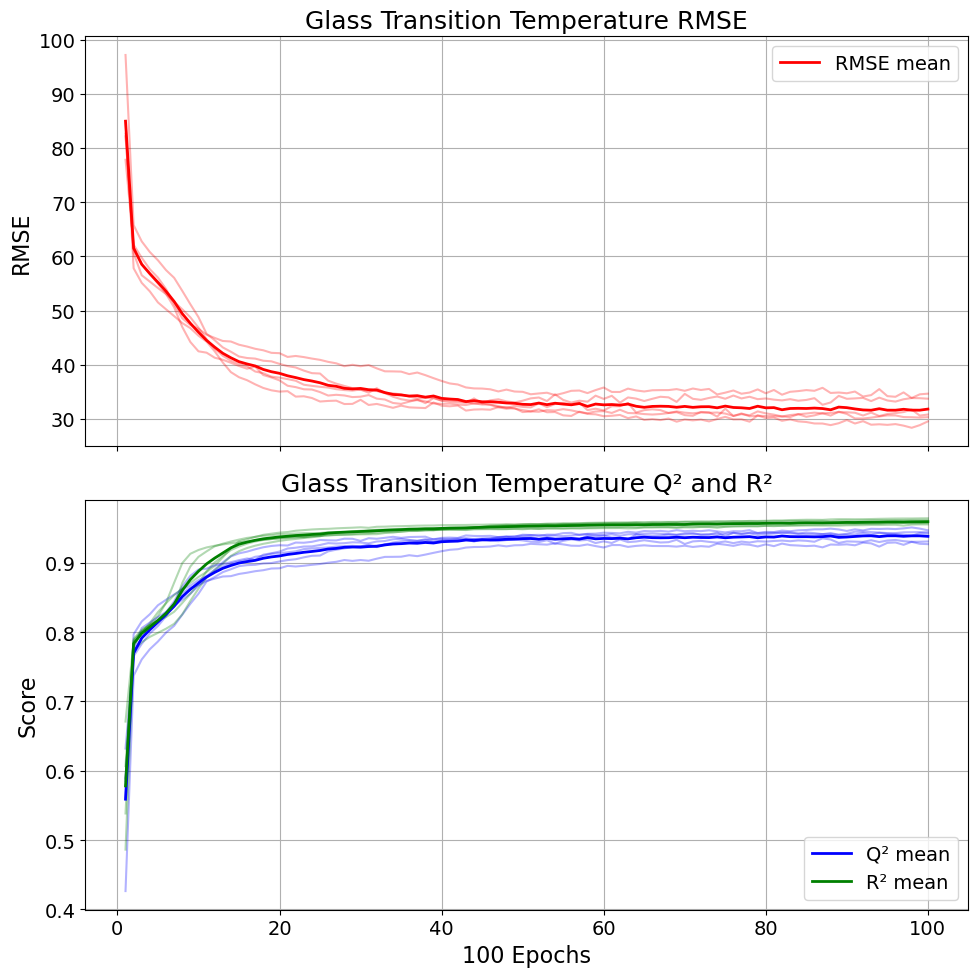

In [56]:
# Average across runs
q2_mean = q2_history.mean(axis=0)
rmse_mean = rmse_history.mean(axis=0)
r2_mean = r2_history.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('Glass Transition Temperature RMSE')
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('100 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('Glass Transition Temperature Q² and R²')
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

In [57]:
print(q2_mean[-1])
print(rmse_mean[-1])
print(r2_mean[-1])

0.9382307590862098
31.815746687557304
0.9594618563559074


### Use Scaled Data

In [58]:
X_train, X_test, y_train, y_test = train_test_split(X_gtt, y_gtt, test_size = 0.2, random_state = 53)

X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
# y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history = np.zeros((n_runs, n_iters))
rmse_history = np.zeros((n_runs, n_iters))
r2_history = np.zeros((n_runs, n_iters))
start_time = np.zeros(n_runs)
end_time = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train_scaled.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train_scaled, y_train_scaled, epochs=100, verbose=0)

        # Predictions
        y_test_pred_scaled = model.predict(X_test_scaled)
        y_train_pred_scaled = model.predict(X_train_scaled)
        
        y_test_pred = y_scaler.inverse_transform(y_test_pred_scaled).flatten()
        y_train_pred = y_scaler.inverse_transform(y_train_pred_scaled).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history[run, i] = q2
        rmse_history[run, i] = rmse
        r2_history[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time[run] = time.time()
    print('total time:', end_time[run] - start_time[run])
    
print(end_time - start_time)

Run 1/5
  Iter 0: Q²=0.933, RMSE=33.255, R²=0.936
  Iter 1: Q²=0.933, RMSE=33.090, R²=0.951
  Iter 2: Q²=0.942, RMSE=30.892, R²=0.959
  Iter 3: Q²=0.945, RMSE=30.049, R²=0.965
  Iter 4: Q²=0.945, RMSE=29.953, R²=0.966
  Iter 5: Q²=0.945, RMSE=30.113, R²=0.967
  Iter 6: Q²=0.945, RMSE=30.113, R²=0.968
  Iter 7: Q²=0.945, RMSE=30.085, R²=0.968
  Iter 8: Q²=0.945, RMSE=29.986, R²=0.968
  Iter 9: Q²=0.945, RMSE=30.145, R²=0.969
  Iter 10: Q²=0.945, RMSE=29.987, R²=0.969
  Iter 11: Q²=0.945, RMSE=30.096, R²=0.969
  Iter 12: Q²=0.945, RMSE=30.171, R²=0.970
  Iter 13: Q²=0.945, RMSE=29.993, R²=0.970
  Iter 14: Q²=0.944, RMSE=30.478, R²=0.970
  Iter 15: Q²=0.944, RMSE=30.224, R²=0.971
  Iter 16: Q²=0.946, RMSE=29.853, R²=0.971
  Iter 17: Q²=0.945, RMSE=30.074, R²=0.971
  Iter 18: Q²=0.947, RMSE=29.468, R²=0.971
  Iter 19: Q²=0.947, RMSE=29.600, R²=0.971
  Iter 20: Q²=0.946, RMSE=29.777, R²=0.971
  Iter 21: Q²=0.946, RMSE=29.707, R²=0.971
  Iter 22: Q²=0.947, RMSE=29.583, R²=0.971
  Iter 23: Q²

  Iter 90: Q²=0.941, RMSE=31.145, R²=0.975
  Iter 91: Q²=0.941, RMSE=31.046, R²=0.975
  Iter 92: Q²=0.941, RMSE=31.075, R²=0.975
  Iter 93: Q²=0.941, RMSE=31.203, R²=0.975
  Iter 94: Q²=0.940, RMSE=31.338, R²=0.975
  Iter 95: Q²=0.941, RMSE=31.275, R²=0.975
  Iter 96: Q²=0.940, RMSE=31.349, R²=0.975
  Iter 97: Q²=0.940, RMSE=31.315, R²=0.975
  Iter 98: Q²=0.941, RMSE=31.097, R²=0.975
  Iter 99: Q²=0.939, RMSE=31.606, R²=0.975
total time: 53.25261902809143
Run 3/5
  Iter 0: Q²=0.932, RMSE=33.325, R²=0.943
  Iter 1: Q²=0.932, RMSE=33.554, R²=0.956
  Iter 2: Q²=0.937, RMSE=32.219, R²=0.961
  Iter 3: Q²=0.938, RMSE=32.031, R²=0.965
  Iter 4: Q²=0.938, RMSE=31.933, R²=0.968
  Iter 5: Q²=0.940, RMSE=31.399, R²=0.970
  Iter 6: Q²=0.939, RMSE=31.576, R²=0.972
  Iter 7: Q²=0.940, RMSE=31.377, R²=0.972
  Iter 8: Q²=0.937, RMSE=32.112, R²=0.973
  Iter 9: Q²=0.937, RMSE=32.183, R²=0.973
  Iter 10: Q²=0.937, RMSE=32.209, R²=0.974
  Iter 11: Q²=0.936, RMSE=32.405, R²=0.974
  Iter 12: Q²=0.935, RMSE=

  Iter 80: Q²=0.941, RMSE=31.269, R²=0.979
  Iter 81: Q²=0.939, RMSE=31.703, R²=0.979
  Iter 82: Q²=0.939, RMSE=31.558, R²=0.979
  Iter 83: Q²=0.940, RMSE=31.342, R²=0.979
  Iter 84: Q²=0.940, RMSE=31.375, R²=0.979
  Iter 85: Q²=0.939, RMSE=31.616, R²=0.979
  Iter 86: Q²=0.938, RMSE=32.027, R²=0.979
  Iter 87: Q²=0.941, RMSE=31.282, R²=0.979
  Iter 88: Q²=0.940, RMSE=31.405, R²=0.979
  Iter 89: Q²=0.939, RMSE=31.581, R²=0.979
  Iter 90: Q²=0.939, RMSE=31.550, R²=0.979
  Iter 91: Q²=0.940, RMSE=31.537, R²=0.979
  Iter 92: Q²=0.939, RMSE=31.663, R²=0.979
  Iter 93: Q²=0.940, RMSE=31.383, R²=0.979
  Iter 94: Q²=0.939, RMSE=31.681, R²=0.979
  Iter 95: Q²=0.938, RMSE=32.036, R²=0.979
  Iter 96: Q²=0.937, RMSE=32.078, R²=0.979
  Iter 97: Q²=0.937, RMSE=32.188, R²=0.979
  Iter 98: Q²=0.938, RMSE=32.032, R²=0.979
  Iter 99: Q²=0.939, RMSE=31.786, R²=0.979
total time: 54.35984206199646
Run 5/5
  Iter 0: Q²=0.932, RMSE=33.351, R²=0.941
  Iter 1: Q²=0.940, RMSE=31.463, R²=0.958
  Iter 2: Q²=0.941

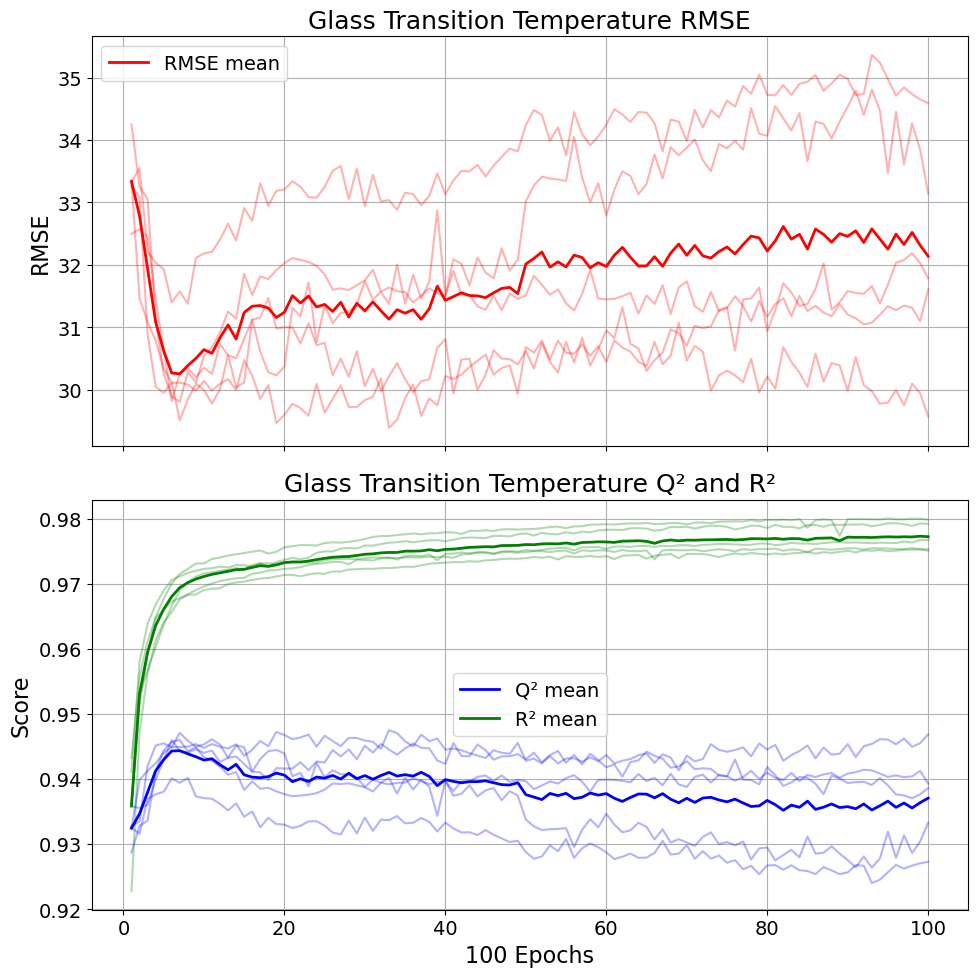

In [59]:
# Average across runs
q2_mean = q2_history.mean(axis=0)
rmse_mean = rmse_history.mean(axis=0)
r2_mean = r2_history.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('Glass Transition Temperature RMSE')
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('100 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('Glass Transition Temperature Q² and R²')
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

In [60]:
print(q2_mean[-1])
print(rmse_mean[-1])
print(r2_mean[-1])

0.937048794524521
32.13905885113966
0.9772179188641121


### Zoom in on early Epochs

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X_gtt, y_gtt, test_size = 0.2, random_state = 53)

X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
# y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history = np.zeros((n_runs, n_iters))
rmse_history = np.zeros((n_runs, n_iters))
r2_history = np.zeros((n_runs, n_iters))
start_time = np.zeros(n_runs)
end_time = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train_scaled.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train_scaled, y_train_scaled, epochs=20, verbose=0)

        # Predictions
        y_test_pred_scaled = model.predict(X_test_scaled)
        y_train_pred_scaled = model.predict(X_train_scaled)
        
        y_test_pred = y_scaler.inverse_transform(y_test_pred_scaled).flatten()
        y_train_pred = y_scaler.inverse_transform(y_train_pred_scaled).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history[run, i] = q2
        rmse_history[run, i] = rmse
        r2_history[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time[run] = time.time()
    print('total time:', end_time[run] - start_time[run])
    
print(end_time - start_time)

Run 1/5
  Iter 0: Q²=0.724, RMSE=67.376, R²=0.575
  Iter 1: Q²=0.874, RMSE=45.528, R²=0.809
  Iter 2: Q²=0.895, RMSE=41.465, R²=0.857
  Iter 3: Q²=0.912, RMSE=38.077, R²=0.891
  Iter 4: Q²=0.928, RMSE=34.354, R²=0.924
  Iter 5: Q²=0.934, RMSE=32.850, R²=0.939
  Iter 6: Q²=0.938, RMSE=32.053, R²=0.945
  Iter 7: Q²=0.938, RMSE=31.877, R²=0.949
  Iter 8: Q²=0.939, RMSE=31.718, R²=0.952
  Iter 9: Q²=0.941, RMSE=31.087, R²=0.954
  Iter 10: Q²=0.942, RMSE=30.848, R²=0.955
  Iter 11: Q²=0.942, RMSE=30.789, R²=0.956
  Iter 12: Q²=0.942, RMSE=30.884, R²=0.958
  Iter 13: Q²=0.943, RMSE=30.700, R²=0.958
  Iter 14: Q²=0.944, RMSE=30.452, R²=0.959
  Iter 15: Q²=0.943, RMSE=30.642, R²=0.960
  Iter 16: Q²=0.944, RMSE=30.319, R²=0.961
  Iter 17: Q²=0.944, RMSE=30.371, R²=0.961
  Iter 18: Q²=0.944, RMSE=30.329, R²=0.962
  Iter 19: Q²=0.945, RMSE=30.065, R²=0.962
  Iter 20: Q²=0.945, RMSE=30.196, R²=0.963
  Iter 21: Q²=0.945, RMSE=30.126, R²=0.963
  Iter 22: Q²=0.945, RMSE=30.008, R²=0.964
  Iter 23: Q²

  Iter 90: Q²=0.936, RMSE=32.488, R²=0.975
  Iter 91: Q²=0.936, RMSE=32.350, R²=0.975
  Iter 92: Q²=0.937, RMSE=32.200, R²=0.975
  Iter 93: Q²=0.936, RMSE=32.530, R²=0.975
  Iter 94: Q²=0.936, RMSE=32.370, R²=0.975
  Iter 95: Q²=0.937, RMSE=32.253, R²=0.975
  Iter 96: Q²=0.935, RMSE=32.672, R²=0.975
  Iter 97: Q²=0.935, RMSE=32.662, R²=0.975
  Iter 98: Q²=0.938, RMSE=31.974, R²=0.975
  Iter 99: Q²=0.937, RMSE=32.322, R²=0.975
total time: 17.19568181037903
Run 3/5
  Iter 0: Q²=0.881, RMSE=44.180, R²=0.787
  Iter 1: Q²=0.915, RMSE=37.296, R²=0.875
  Iter 2: Q²=0.925, RMSE=35.112, R²=0.903
  Iter 3: Q²=0.931, RMSE=33.671, R²=0.925
  Iter 4: Q²=0.936, RMSE=32.369, R²=0.940
  Iter 5: Q²=0.936, RMSE=32.344, R²=0.947
  Iter 6: Q²=0.939, RMSE=31.801, R²=0.951
  Iter 7: Q²=0.939, RMSE=31.662, R²=0.954
  Iter 8: Q²=0.939, RMSE=31.661, R²=0.956
  Iter 9: Q²=0.938, RMSE=32.053, R²=0.958
  Iter 10: Q²=0.938, RMSE=31.953, R²=0.959
  Iter 11: Q²=0.938, RMSE=31.812, R²=0.960
  Iter 12: Q²=0.938, RMSE=

  Iter 80: Q²=0.950, RMSE=28.591, R²=0.973
  Iter 81: Q²=0.951, RMSE=28.397, R²=0.972
  Iter 82: Q²=0.951, RMSE=28.409, R²=0.973
  Iter 83: Q²=0.950, RMSE=28.543, R²=0.973
  Iter 84: Q²=0.950, RMSE=28.618, R²=0.973
  Iter 85: Q²=0.951, RMSE=28.537, R²=0.973
  Iter 86: Q²=0.951, RMSE=28.380, R²=0.973
  Iter 87: Q²=0.950, RMSE=28.725, R²=0.973
  Iter 88: Q²=0.950, RMSE=28.712, R²=0.973
  Iter 89: Q²=0.951, RMSE=28.397, R²=0.973
  Iter 90: Q²=0.950, RMSE=28.568, R²=0.973
  Iter 91: Q²=0.951, RMSE=28.394, R²=0.973
  Iter 92: Q²=0.950, RMSE=28.736, R²=0.973
  Iter 93: Q²=0.950, RMSE=28.577, R²=0.973
  Iter 94: Q²=0.950, RMSE=28.609, R²=0.973
  Iter 95: Q²=0.950, RMSE=28.611, R²=0.973
  Iter 96: Q²=0.950, RMSE=28.589, R²=0.973
  Iter 97: Q²=0.951, RMSE=28.528, R²=0.973
  Iter 98: Q²=0.950, RMSE=28.557, R²=0.973
  Iter 99: Q²=0.950, RMSE=28.590, R²=0.973
total time: 17.951011419296265
Run 5/5
  Iter 0: Q²=0.738, RMSE=65.618, R²=0.800
  Iter 1: Q²=0.871, RMSE=46.078, R²=0.889
  Iter 2: Q²=0.90

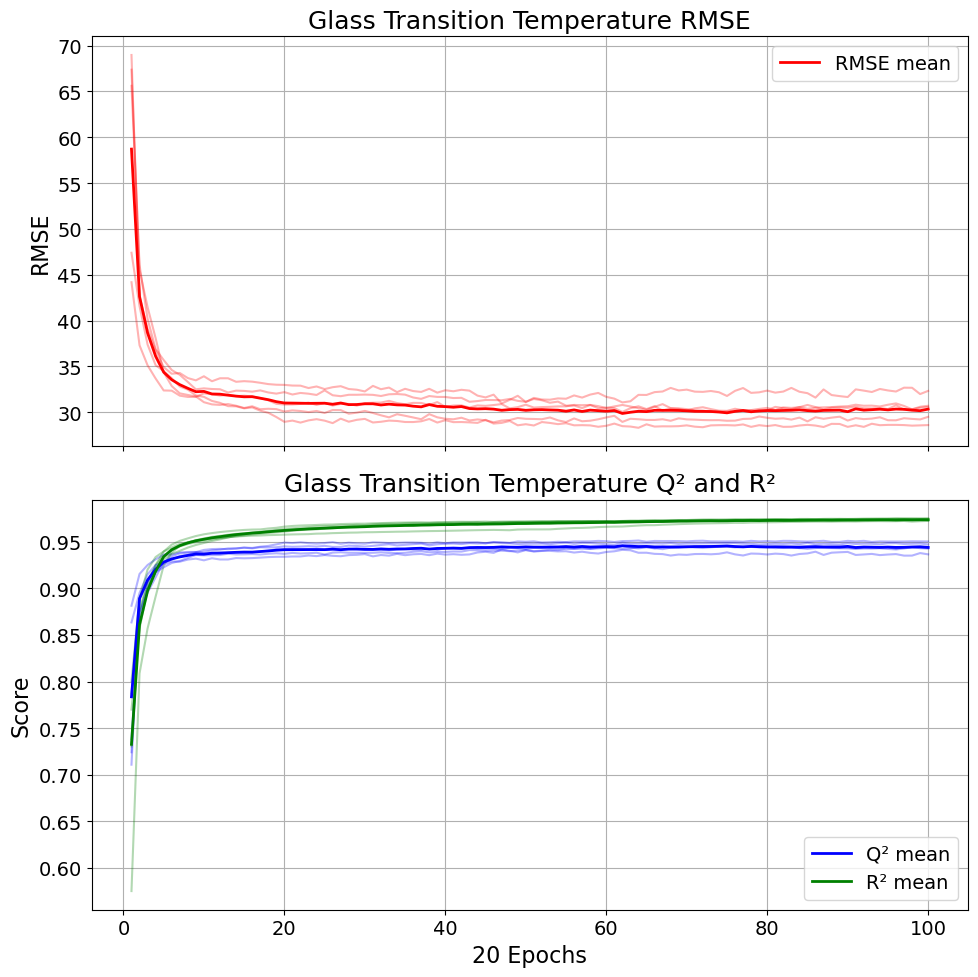

In [62]:
# Average across runs
q2_mean = q2_history.mean(axis=0)
rmse_mean = rmse_history.mean(axis=0)
r2_mean = r2_history.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('Glass Transition Temperature RMSE')
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('20 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('Glass Transition Temperature Q² and R²')
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

In [63]:
print(q2_mean[-1])
print(rmse_mean[-1])
print(r2_mean[-1])

0.9439744142268646
30.33469758366279
0.9737039666596944


### Closer evaluating the unscaled graphs

Zooming in to better see behavior after initial training

In [64]:
# from sklearn.metrics import r2_score, mean_squared_error as mse
# import numpy as np

X_train, X_test, y_train, y_test = train_test_split(X_krev, y_krev, test_size = 0.2, random_state = 53)

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history = np.zeros((n_runs, n_iters))
rmse_history = np.zeros((n_runs, n_iters))
r2_history = np.zeros((n_runs, n_iters))
start_time = np.zeros(n_runs)
end_time = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train, y_train, epochs=100, verbose=0)

        # Predictions
        y_test_pred = model.predict(X_test).flatten()
        y_train_pred = model.predict(X_train).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history[run, i] = q2
        rmse_history[run, i] = rmse
        r2_history[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time[run] = time.time()
    print('total time:', end_time[run] - start_time[run])
end_time - start_time

Run 1/5
  Iter 0: Q²=-1.608, RMSE=76513.805, R²=-1.418
  Iter 1: Q²=-1.507, RMSE=75019.002, R²=-1.316
  Iter 2: Q²=-1.269, RMSE=71363.951, R²=-1.077
  Iter 3: Q²=-0.898, RMSE=65270.850, R²=-0.706
  Iter 4: Q²=-0.450, RMSE=57058.546, R²=-0.262
  Iter 5: Q²=-0.006, RMSE=47513.181, R²=0.174
  Iter 6: Q²=0.358, RMSE=37963.998, R²=0.523
  Iter 7: Q²=0.583, RMSE=30599.600, R²=0.730
  Iter 8: Q²=0.689, RMSE=26405.084, R²=0.819
  Iter 9: Q²=0.727, RMSE=24775.805, R²=0.845
  Iter 10: Q²=0.736, RMSE=24345.983, R²=0.849
  Iter 11: Q²=0.738, RMSE=24238.846, R²=0.850
  Iter 12: Q²=0.739, RMSE=24195.960, R²=0.850
  Iter 13: Q²=0.739, RMSE=24183.870, R²=0.850
  Iter 14: Q²=0.740, RMSE=24181.324, R²=0.851
  Iter 15: Q²=0.740, RMSE=24172.761, R²=0.851
  Iter 16: Q²=0.740, RMSE=24175.494, R²=0.852
  Iter 17: Q²=0.740, RMSE=24167.442, R²=0.852
  Iter 18: Q²=0.740, RMSE=24176.692, R²=0.853
  Iter 19: Q²=0.740, RMSE=24176.755, R²=0.853
  Iter 20: Q²=0.740, RMSE=24176.582, R²=0.854
  Iter 21: Q²=0.740, RMSE

  Iter 78: Q²=0.738, RMSE=24238.136, R²=0.870
  Iter 79: Q²=0.738, RMSE=24266.158, R²=0.870
  Iter 80: Q²=0.738, RMSE=24260.872, R²=0.870
  Iter 81: Q²=0.737, RMSE=24274.488, R²=0.870
  Iter 82: Q²=0.738, RMSE=24236.776, R²=0.870
  Iter 83: Q²=0.737, RMSE=24302.716, R²=0.870
  Iter 84: Q²=0.736, RMSE=24325.530, R²=0.870
  Iter 85: Q²=0.738, RMSE=24272.390, R²=0.870
  Iter 86: Q²=0.738, RMSE=24245.724, R²=0.870
  Iter 87: Q²=0.737, RMSE=24297.064, R²=0.870
  Iter 88: Q²=0.737, RMSE=24319.453, R²=0.871
  Iter 89: Q²=0.737, RMSE=24312.943, R²=0.871
  Iter 90: Q²=0.737, RMSE=24295.613, R²=0.871
  Iter 91: Q²=0.737, RMSE=24306.614, R²=0.871
  Iter 92: Q²=0.736, RMSE=24327.304, R²=0.871
  Iter 93: Q²=0.736, RMSE=24330.887, R²=0.871
  Iter 94: Q²=0.736, RMSE=24326.961, R²=0.871
  Iter 95: Q²=0.737, RMSE=24312.766, R²=0.871
  Iter 96: Q²=0.736, RMSE=24331.141, R²=0.871
  Iter 97: Q²=0.736, RMSE=24364.124, R²=0.871
  Iter 98: Q²=0.736, RMSE=24348.855, R²=0.871
  Iter 99: Q²=0.736, RMSE=24346.33

  Iter 55: Q²=0.741, RMSE=24104.007, R²=0.863
  Iter 56: Q²=0.741, RMSE=24089.060, R²=0.864
  Iter 57: Q²=0.742, RMSE=24080.790, R²=0.864
  Iter 58: Q²=0.742, RMSE=24070.281, R²=0.864
  Iter 59: Q²=0.741, RMSE=24094.095, R²=0.864
  Iter 60: Q²=0.741, RMSE=24103.116, R²=0.865
  Iter 61: Q²=0.741, RMSE=24102.338, R²=0.865
  Iter 62: Q²=0.742, RMSE=24085.945, R²=0.865
  Iter 63: Q²=0.741, RMSE=24102.323, R²=0.865
  Iter 64: Q²=0.741, RMSE=24093.970, R²=0.865
  Iter 65: Q²=0.741, RMSE=24106.032, R²=0.866
  Iter 66: Q²=0.741, RMSE=24111.855, R²=0.866
  Iter 67: Q²=0.741, RMSE=24123.800, R²=0.866
  Iter 68: Q²=0.741, RMSE=24102.187, R²=0.866
  Iter 69: Q²=0.741, RMSE=24119.739, R²=0.866
  Iter 70: Q²=0.741, RMSE=24113.082, R²=0.867
  Iter 71: Q²=0.741, RMSE=24121.095, R²=0.867
  Iter 72: Q²=0.740, RMSE=24141.271, R²=0.867
  Iter 73: Q²=0.740, RMSE=24138.780, R²=0.867
  Iter 74: Q²=0.740, RMSE=24164.112, R²=0.867
  Iter 75: Q²=0.741, RMSE=24126.048, R²=0.867
  Iter 76: Q²=0.740, RMSE=24140.72

array([86.09330893, 48.50583577, 66.9358151 , 44.86327982, 41.78281069])

In [65]:
# This was from the first run
end_time - start_time

array([86.09330893, 48.50583577, 66.9358151 , 44.86327982, 41.78281069])

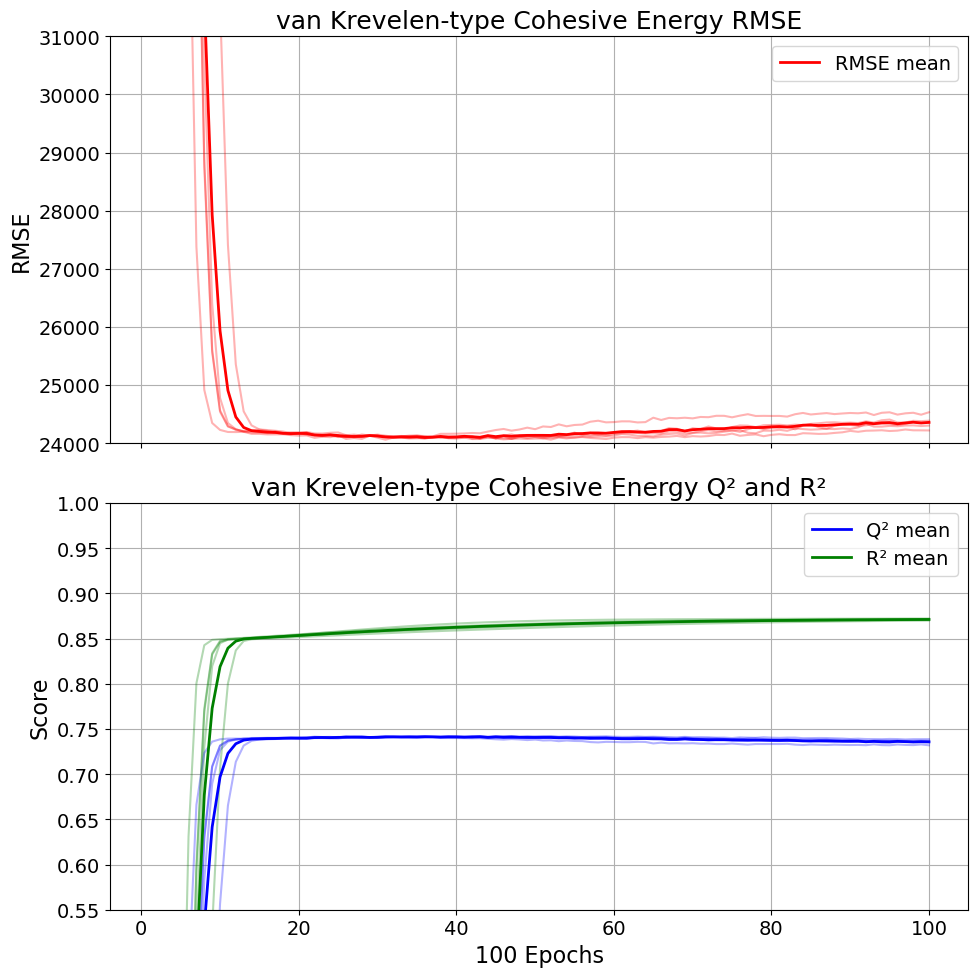

In [70]:
# Average across runs
q2_mean = q2_history.mean(axis=0)
rmse_mean = rmse_history.mean(axis=0)
r2_mean = r2_history.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('van Krevelen-type Cohesive Energy RMSE')
axes[0].set_ylim(24000, 31000)
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('100 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('van Krevelen-type Cohesive Energy Q² and R²')
axes[1].set_ylim(0.55, 1)
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

In [68]:
print(q2_mean[-1])
print(rmse_mean[-1])
print(r2_mean[-1])

0.7357034863893792
24356.873637337303
0.8710984519740512


In [71]:
X_train, X_test, y_train, y_test = train_test_split(X_fed, y_fed, test_size = 0.2, random_state = 53)

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history_f = np.zeros((n_runs, n_iters))
rmse_history_f = np.zeros((n_runs, n_iters))
r2_history_f = np.zeros((n_runs, n_iters))
start_time_f = np.zeros(n_runs)
end_time_f = np.zeros(n_runs)

for run in range(n_runs):
    start_time_f[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train, y_train, epochs=100, verbose=0)

        # Predictions
        y_test_pred = model.predict(X_test).flatten()
        y_train_pred = model.predict(X_train).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history_f[run, i] = q2
        rmse_history_f[run, i] = rmse
        r2_history_f[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time_f[run] = time.time()
    print('total time:', end_time[run] - start_time[run])

Run 1/5
  Iter 0: Q²=-1.882, RMSE=77568.764, R²=-1.820
  Iter 1: Q²=-1.792, RMSE=76345.884, R²=-1.726
  Iter 2: Q²=-1.568, RMSE=73220.696, R²=-1.494
  Iter 3: Q²=-1.205, RMSE=67845.811, R²=-1.118
  Iter 4: Q²=-0.740, RMSE=60275.874, R²=-0.640
  Iter 5: Q²=-0.243, RMSE=50946.260, R²=-0.135
  Iter 6: Q²=0.208, RMSE=40677.883, R²=0.315
  Iter 7: Q²=0.546, RMSE=30805.081, R²=0.641
  Iter 8: Q²=0.746, RMSE=23046.496, R²=0.821
  Iter 9: Q²=0.837, RMSE=18468.441, R²=0.892
  Iter 10: Q²=0.869, RMSE=16540.178, R²=0.911
  Iter 11: Q²=0.878, RMSE=15987.381, R²=0.913
  Iter 12: Q²=0.880, RMSE=15841.523, R²=0.914
  Iter 13: Q²=0.881, RMSE=15783.102, R²=0.914
  Iter 14: Q²=0.881, RMSE=15753.825, R²=0.914
  Iter 15: Q²=0.881, RMSE=15751.831, R²=0.914
  Iter 16: Q²=0.882, RMSE=15707.849, R²=0.914
  Iter 17: Q²=0.881, RMSE=15745.558, R²=0.915
  Iter 18: Q²=0.881, RMSE=15735.926, R²=0.915
  Iter 19: Q²=0.882, RMSE=15694.749, R²=0.915
  Iter 20: Q²=0.882, RMSE=15710.015, R²=0.915
  Iter 21: Q²=0.882, RMS

  Iter 77: Q²=0.885, RMSE=15491.441, R²=0.921
  Iter 78: Q²=0.885, RMSE=15478.243, R²=0.921
  Iter 79: Q²=0.885, RMSE=15488.480, R²=0.921
  Iter 80: Q²=0.885, RMSE=15466.302, R²=0.921
  Iter 81: Q²=0.885, RMSE=15500.392, R²=0.921
  Iter 82: Q²=0.885, RMSE=15469.032, R²=0.921
  Iter 83: Q²=0.885, RMSE=15501.553, R²=0.921
  Iter 84: Q²=0.885, RMSE=15500.181, R²=0.921
  Iter 85: Q²=0.885, RMSE=15524.752, R²=0.921
  Iter 86: Q²=0.884, RMSE=15536.064, R²=0.921
  Iter 87: Q²=0.885, RMSE=15507.392, R²=0.921
  Iter 88: Q²=0.885, RMSE=15524.830, R²=0.921
  Iter 89: Q²=0.885, RMSE=15489.175, R²=0.921
  Iter 90: Q²=0.884, RMSE=15555.197, R²=0.921
  Iter 91: Q²=0.885, RMSE=15511.005, R²=0.921
  Iter 92: Q²=0.884, RMSE=15540.209, R²=0.921
  Iter 93: Q²=0.885, RMSE=15494.932, R²=0.921
  Iter 94: Q²=0.885, RMSE=15495.308, R²=0.921
  Iter 95: Q²=0.885, RMSE=15501.017, R²=0.921
  Iter 96: Q²=0.885, RMSE=15496.653, R²=0.921
  Iter 97: Q²=0.885, RMSE=15524.315, R²=0.921
  Iter 98: Q²=0.885, RMSE=15491.07

  Iter 54: Q²=0.885, RMSE=15515.724, R²=0.921
  Iter 55: Q²=0.885, RMSE=15485.958, R²=0.921
  Iter 56: Q²=0.885, RMSE=15511.321, R²=0.921
  Iter 57: Q²=0.884, RMSE=15555.510, R²=0.921
  Iter 58: Q²=0.885, RMSE=15465.348, R²=0.921
  Iter 59: Q²=0.885, RMSE=15519.995, R²=0.921
  Iter 60: Q²=0.885, RMSE=15514.459, R²=0.921
  Iter 61: Q²=0.885, RMSE=15516.921, R²=0.921
  Iter 62: Q²=0.885, RMSE=15482.138, R²=0.921
  Iter 63: Q²=0.884, RMSE=15536.248, R²=0.921
  Iter 64: Q²=0.885, RMSE=15496.911, R²=0.921
  Iter 65: Q²=0.885, RMSE=15484.589, R²=0.921
  Iter 66: Q²=0.885, RMSE=15485.192, R²=0.921
  Iter 67: Q²=0.885, RMSE=15469.986, R²=0.921
  Iter 68: Q²=0.885, RMSE=15493.420, R²=0.922
  Iter 69: Q²=0.884, RMSE=15544.846, R²=0.922
  Iter 70: Q²=0.885, RMSE=15491.179, R²=0.922
  Iter 71: Q²=0.885, RMSE=15464.301, R²=0.922
  Iter 72: Q²=0.885, RMSE=15489.432, R²=0.922
  Iter 73: Q²=0.885, RMSE=15474.652, R²=0.922
  Iter 74: Q²=0.885, RMSE=15497.667, R²=0.922
  Iter 75: Q²=0.885, RMSE=15484.69

In [72]:
# This was from the first run
end_time_f - start_time_f

array([46.30761147, 47.60258889, 45.08869147, 48.47817516, 46.29920626])

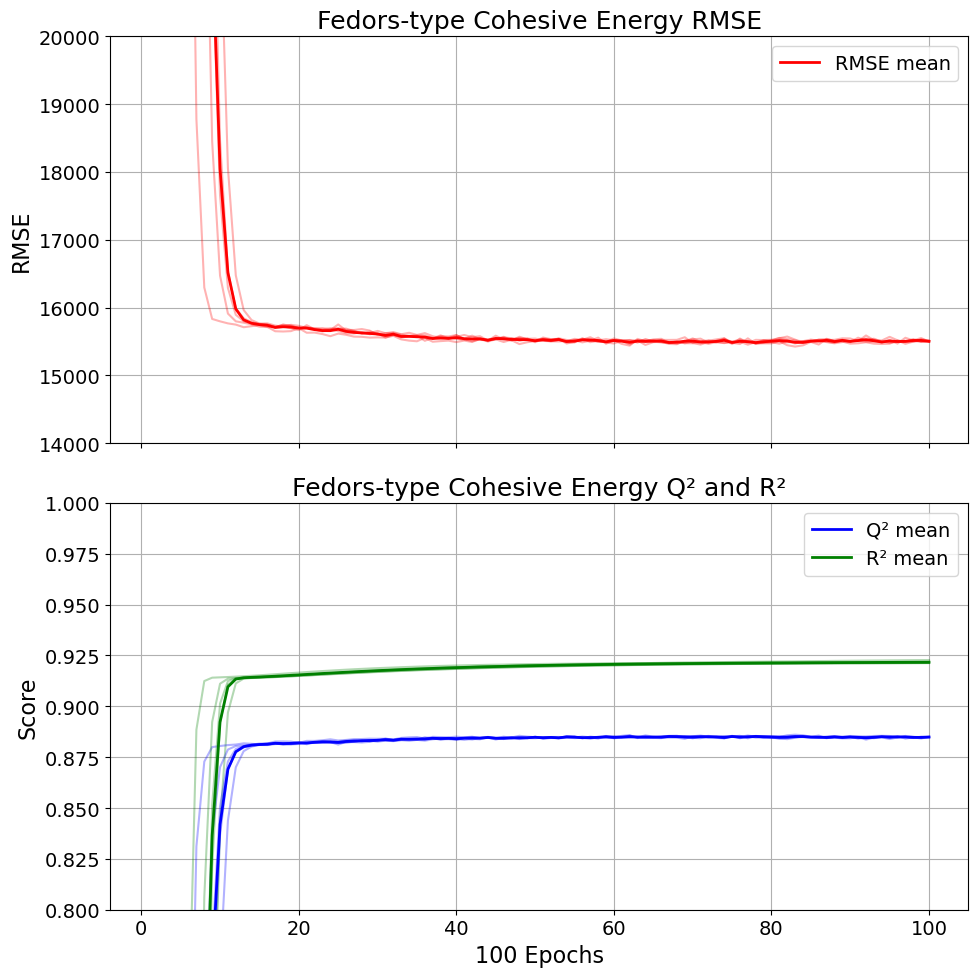

In [73]:
# Average across runs
q2_mean_f = q2_history_f.mean(axis=0)
rmse_mean_f = rmse_history_f.mean(axis=0)
r2_mean_f = r2_history_f.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history_f[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean_f, label='RMSE mean', color='red', linewidth=2)

axes[0].set_ylabel('RMSE')
axes[0].set_title('Fedors-type Cohesive Energy RMSE')
axes[0].set_ylim(14000,20000)
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history_f[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history_f[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean_f, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean_f, label='R² mean', color='green', linewidth=2)

axes[1].set_xlabel('100 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('Fedors-type Cohesive Energy Q² and R²')
axes[1].set_ylim(0.8,1)
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()

In [74]:
print(q2_mean_f[-1])
print(rmse_mean_f[-1])
print(r2_mean_f[-1])

0.8849017736008493
15502.236451022953
0.9216916121000119


In [75]:
X_train, X_test, y_train, y_test = train_test_split(X_gtt, y_gtt, test_size = 0.2, random_state = 53)

n_runs = 5
n_iters = 100  # your inner loop

# Storage: shape (runs, iterations)
q2_history_g = np.zeros((n_runs, n_iters))
rmse_history_g = np.zeros((n_runs, n_iters))
r2_history_g = np.zeros((n_runs, n_iters))
start_time_g = np.zeros(n_runs)
end_time_g = np.zeros(n_runs)

for run in range(n_runs):
    start_time[run] = time.time()
    print(f"Run {run+1}/{n_runs}")
    
    # Reinitialize model each run
    model = Sequential([
        Dense(10, activation='relu', input_shape=(X_train.shape[1],)),
        Dense(10, activation='relu'),
        Dense(1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
    
    for i in range(n_iters):
        model.fit(X_train, y_train, epochs=100, verbose=0)

        # Predictions
        y_test_pred = model.predict(X_test).flatten()
        y_train_pred = model.predict(X_train).flatten()
        
        # Metrics
        q2 = r2_score(y_test, y_test_pred)
        rmse = np.sqrt(mse(y_test, y_test_pred))
        r2 = r2_score(y_train, y_train_pred)
        
        # Store
        q2_history_g[run, i] = q2
        rmse_history_g[run, i] = rmse
        r2_history_g[run, i] = r2

        print(f"  Iter {i}: Q²={q2:.3f}, RMSE={rmse:.3f}, R²={r2:.3f}")
    end_time_g[run] = time.time()
    print('total time:', end_time_g[run] - start_time_g[run])

Run 1/5
  Iter 0: Q²=0.090, RMSE=122.370, R²=-0.052
  Iter 1: Q²=0.727, RMSE=66.966, R²=0.774
  Iter 2: Q²=0.762, RMSE=62.573, R²=0.790
  Iter 3: Q²=0.778, RMSE=60.396, R²=0.798
  Iter 4: Q²=0.792, RMSE=58.499, R²=0.805
  Iter 5: Q²=0.805, RMSE=56.694, R²=0.812
  Iter 6: Q²=0.814, RMSE=55.273, R²=0.818
  Iter 7: Q²=0.823, RMSE=53.979, R²=0.823
  Iter 8: Q²=0.831, RMSE=52.660, R²=0.835
  Iter 9: Q²=0.840, RMSE=51.319, R²=0.846
  Iter 10: Q²=0.850, RMSE=49.609, R²=0.861
  Iter 11: Q²=0.859, RMSE=48.184, R²=0.871
  Iter 12: Q²=0.864, RMSE=47.315, R²=0.879
  Iter 13: Q²=0.868, RMSE=46.575, R²=0.886
  Iter 14: Q²=0.873, RMSE=45.642, R²=0.893
  Iter 15: Q²=0.880, RMSE=44.481, R²=0.901
  Iter 16: Q²=0.882, RMSE=44.143, R²=0.907
  Iter 17: Q²=0.885, RMSE=43.448, R²=0.912
  Iter 18: Q²=0.890, RMSE=42.600, R²=0.918
  Iter 19: Q²=0.894, RMSE=41.761, R²=0.924
  Iter 20: Q²=0.894, RMSE=41.689, R²=0.927
  Iter 21: Q²=0.895, RMSE=41.583, R²=0.929
  Iter 22: Q²=0.898, RMSE=40.932, R²=0.931
  Iter 23: 

  Iter 90: Q²=0.939, RMSE=31.778, R²=0.955
  Iter 91: Q²=0.942, RMSE=30.799, R²=0.955
  Iter 92: Q²=0.943, RMSE=30.748, R²=0.955
  Iter 93: Q²=0.942, RMSE=30.899, R²=0.956
  Iter 94: Q²=0.942, RMSE=30.788, R²=0.954
  Iter 95: Q²=0.940, RMSE=31.470, R²=0.955
  Iter 96: Q²=0.942, RMSE=30.893, R²=0.956
  Iter 97: Q²=0.944, RMSE=30.230, R²=0.954
  Iter 98: Q²=0.937, RMSE=32.300, R²=0.956
  Iter 99: Q²=0.936, RMSE=32.571, R²=0.955
total time: 1775248772.8738282
Run 3/5
  Iter 0: Q²=0.590, RMSE=82.161, R²=0.574
  Iter 1: Q²=0.788, RMSE=59.083, R²=0.780
  Iter 2: Q²=0.797, RMSE=57.762, R²=0.795
  Iter 3: Q²=0.808, RMSE=56.255, R²=0.808
  Iter 4: Q²=0.828, RMSE=53.125, R²=0.837
  Iter 5: Q²=0.848, RMSE=49.953, R²=0.864
  Iter 6: Q²=0.866, RMSE=46.964, R²=0.890
  Iter 7: Q²=0.877, RMSE=45.029, R²=0.905
  Iter 8: Q²=0.879, RMSE=44.576, R²=0.910
  Iter 9: Q²=0.883, RMSE=43.929, R²=0.915
  Iter 10: Q²=0.884, RMSE=43.621, R²=0.917
  Iter 11: Q²=0.886, RMSE=43.382, R²=0.918
  Iter 12: Q²=0.889, RMSE

  Iter 80: Q²=0.950, RMSE=28.689, R²=0.953
  Iter 81: Q²=0.951, RMSE=28.425, R²=0.953
  Iter 82: Q²=0.948, RMSE=29.314, R²=0.953
  Iter 83: Q²=0.950, RMSE=28.720, R²=0.953
  Iter 84: Q²=0.949, RMSE=28.837, R²=0.953
  Iter 85: Q²=0.951, RMSE=28.397, R²=0.953
  Iter 86: Q²=0.952, RMSE=28.222, R²=0.953
  Iter 87: Q²=0.952, RMSE=28.111, R²=0.953
  Iter 88: Q²=0.951, RMSE=28.379, R²=0.953
  Iter 89: Q²=0.944, RMSE=30.239, R²=0.952
  Iter 90: Q²=0.951, RMSE=28.370, R²=0.954
  Iter 91: Q²=0.943, RMSE=30.494, R²=0.952
  Iter 92: Q²=0.952, RMSE=28.006, R²=0.954
  Iter 93: Q²=0.951, RMSE=28.358, R²=0.954
  Iter 94: Q²=0.950, RMSE=28.651, R²=0.954
  Iter 95: Q²=0.952, RMSE=28.052, R²=0.954
  Iter 96: Q²=0.951, RMSE=28.490, R²=0.954
  Iter 97: Q²=0.951, RMSE=28.252, R²=0.954
  Iter 98: Q²=0.950, RMSE=28.735, R²=0.954
  Iter 99: Q²=0.952, RMSE=28.183, R²=0.954
total time: 1775248896.7469409
Run 5/5
  Iter 0: Q²=0.632, RMSE=77.793, R²=0.653
  Iter 1: Q²=0.740, RMSE=65.437, R²=0.762
  Iter 2: Q²=0.76

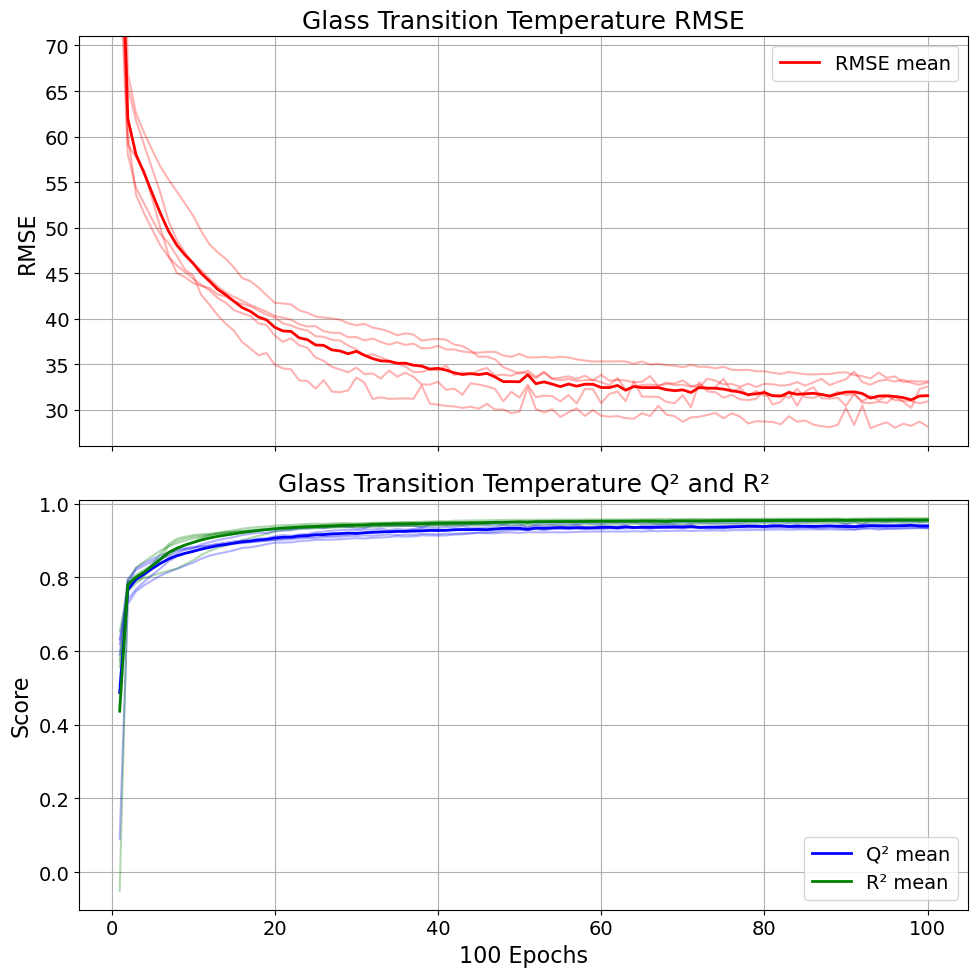

In [76]:
# Average across runs
q2_mean_g = q2_history_g.mean(axis=0)
rmse_mean_g = rmse_history_g.mean(axis=0)
r2_mean_g = r2_history_g.mean(axis=0)
x_axis_vec = np.arange(1, n_iters + 1)

# ---- Global font size settings ----
plt.rcParams.update({
    'font.size': 14,          # base size
    'axes.titlesize': 18,     # subplot titles
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x-axis numbers
    'ytick.labelsize': 14,    # y-axis numbers
    'legend.fontsize': 14     # legend text
})

# ---- Create stacked subplots ----
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# =========================
# Plot 1: RMSE
# =========================
for run in range(n_runs):
    axes[0].plot(x_axis_vec, rmse_history_g[run], alpha=0.3, color='red')

axes[0].plot(x_axis_vec, rmse_mean_g, label='RMSE mean', color='red', linewidth=2)
axes[0].set_ylabel('RMSE')
axes[0].set_title('Glass Transition Temperature RMSE')
axes[0].set_ylim(26,71)
axes[0].legend()
axes[0].grid(True)

# =========================
# Plot 2: Q² and R²
# =========================
for run in range(n_runs):
    axes[1].plot(x_axis_vec, q2_history_g[run], alpha=0.3, color='blue')
    axes[1].plot(x_axis_vec, r2_history_g[run], alpha=0.3, color='green')

axes[1].plot(x_axis_vec, q2_mean_g, label='Q² mean', color='blue', linewidth=2)
axes[1].plot(x_axis_vec, r2_mean_g, label='R² mean', color='green', linewidth=2)
axes[1].set_xlabel('100 Epochs')
axes[1].set_ylabel('Score')
axes[1].set_title('Glass Transition Temperature Q² and R²')
axes[1].legend()
axes[1].grid(True)

# ---- Improve spacing ----
plt.tight_layout()

plt.show()